# Deliverable 2 — Contoso-analyse in Python

**Jordy Perret** · HBO-ICT, Avans Hogeschool · Leerjaar 3, semester 1
Data Engineering, leeruitkomst 1 — deliverable 2

---

In deliverable 1 is de Contoso-dataset gemodelleerd als sterschema en zijn tien
visualisaties gebouwd in Power BI. Deze notebook realiseert diezelfde tien
visualisaties in Python.

Het verschil met Power BI zit in twee dingen, en die bepalen de opbouw van deze
notebook:

1. **Python kent geen relaties.** Power BI legt relaties tussen de feitentabel en
   de dimensies en gebruikt die om filters door te geven. Python heeft dat niet.
   Alles wat ik in Power BI met een relatie oploste, moet hier expliciet worden
   samengevoegd (`merge`) tot één brede tabel.
2. **Python begint bij de ruwe CSV's.** De transformaties uit Power Query
   (datums afleiden, kolommen hernoemen, de feestdagentabel uitbreiden) zitten
   in het `.pbix`-bestand en niet in de bronbestanden. Ze worden hieronder dus
   opnieuw uitgevoerd.

De notebook volgt daarom de ETL-volgorde: eerst **extract** (hoofdstuk 2), dan
**transform** (hoofdstuk 3), dan **load** naar één analysetabel (hoofdstuk 4),
en daarna de visualisaties per user story (hoofdstuk 5 en 6).

## 1. Voorbereiding

### 1.1 Benodigde pakketten

Deze notebook gebruikt drie pakketten:

| Pakket | Waarvoor |
|---|---|
| `pandas` | inlezen van de CSV's, samenvoegen en aggregeren |
| `matplotlib` | tekenen van de grafieken |
| `numpy` | rekenen met arrays, hier vooral voor de kleurbepaling bij groei/krimp |

Installeren gebeurt eenmalig in de terminal van de omgeving:

```
pip install pandas matplotlib numpy
```

In [163]:
# Importeren van de pakketten. De afkortingen pd, np en plt zijn de
# gangbare conventie in de Python-datawereld.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from pathlib import Path

# Weergave-instellingen: zonder deze regels kort pandas brede tabellen af
# met "..." en toont het grote getallen in wetenschappelijke notatie.
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

print("pandas: ", pd.__version__)
print("matplotlib: ", plt.matplotlib.__version__)
print("numpy: ", np.__version__)

pandas:  3.0.5
matplotlib:  3.11.2
numpy:  2.5.3


### 1.2 Bestandslocaties

De paden staan hieronder op één plek bij elkaar, zodat de notebook op een
andere machine werkt door alleen `DATA_MAP` aan te passen. Ik gebruik
*relatieve* paden (`data/...`) en geen absolute paden
(`C:\Users\Jordy\...`), omdat een absoluut pad de notebook onbruikbaar maakt
voor iedereen die hem nakijkt.

De verwachte mapstructuur:

```
deliverable2/
├── analyse_contoso.ipynb     <- deze notebook
├── data/
│   ├── Contoso_Sales.csv
│   ├── Contoso_Calendar.csv
│   ├── Contoso_Channel.csv
│   ├── Contoso_Geography.csv
│   ├── Contoso_Stores.csv
│   ├── Contoso_Product.csv
│   ├── Contoso_ProductSubcategory.csv
│   ├── Contoso_Product_Category.csv
│   ├── Contoso_Promotion.csv
│   └── publicHolidays.csv
└── output/                   <- wordt automatisch aangemaakt
```

In [164]:
# Eén plek voor alle paden.
DATA_MAP = Path("data")
UITVOER_MAP = Path("output")
UITVOER_MAP.mkdir(exist_ok=True)   # maakt de map aan als die nog niet bestaat

BESTANDEN = {
    "sales":        DATA_MAP / "Contoso_Sales.csv",
    "calendar":     DATA_MAP / "Contoso_Calendar.csv",
    "channel":      DATA_MAP / "Contoso_Channel.csv",
    "geography":    DATA_MAP / "Contoso_Geography.csv",
    "stores":       DATA_MAP / "Contoso_Stores.csv",
    "product":      DATA_MAP / "Contoso_Product.csv",
    "subcategory":  DATA_MAP / "Contoso_ProductSubcategory.csv",
    "category":     DATA_MAP / "Contoso_Product_Category.csv",
    "promotion":    DATA_MAP / "Contoso_Promotion.csv",
    "feestdagen":   DATA_MAP / "publicHolidays.csv",
}

# Controle vooraf: bestaat elk bestand? Dit voorkomt dat de notebook halverwege afbreekt op een typefout in een bestandsnaam.
for naam, pad in BESTANDEN.items():
    status = "gevonden" if pad.exists() else "ONTBREEKT"
    print(f"{naam}: {status} - {pad}")

sales: gevonden - data/Contoso_Sales.csv
calendar: gevonden - data/Contoso_Calendar.csv
channel: gevonden - data/Contoso_Channel.csv
geography: gevonden - data/Contoso_Geography.csv
stores: gevonden - data/Contoso_Stores.csv
product: gevonden - data/Contoso_Product.csv
subcategory: gevonden - data/Contoso_ProductSubcategory.csv
category: gevonden - data/Contoso_Product_Category.csv
promotion: gevonden - data/Contoso_Promotion.csv
feestdagen: gevonden - data/publicHolidays.csv


### 1.3 Scheidingsteken en decimaalteken

De Contoso-bestanden zijn geexporteerd met Nederlandse regio-instellingen. Dat
betekent dat een bedrag in het bestand staat als `3214,4` en niet als `3214.4`.
Python rekent met een punt als decimaalteken en leest `3214,4` daarom als tekst,
wat bij het inlezen deze fout geeft:

```
ValueError: could not convert string to float: '3214,4'
```

Met `decimal=","` vertelt `pandas` hoe het getal gelezen moet worden. Omdat een
export met een komma als decimaalteken vaak ook een puntkomma als
scheidingsteken gebruikt, staan beide instellingen hieronder bij elkaar in
`CSV_OPTIES`, die bij elk `read_csv` wordt meegegeven. Zo is er één plek waar
dit aangepast hoeft te worden.

**Welke instelling hoort bij jouw bestanden?** De cel hieronder drukt de eerste
twee regels onbewerkt af. Staan de velden gescheiden door een puntkomma, zet
`sep` dan op `";"`. Staan ze gescheiden door een komma, laat `sep` dan op `","`.

In [165]:
# Eerste twee regels onbewerkt tonen, om scheidingsteken en decimaalteken
# vast te stellen. repr() maakt tabs, aanhalingstekens en regeleindes zichtbaar.
with open(BESTANDEN["sales"], encoding="utf-8") as f:
    for i in range(2):
        print(repr(f.readline()))

'SalesKey,DateKey,channelKey,StoreKey,ProductKey,PromotionKey,UnitCost,UnitPrice,SalesQuantity,ReturnQuantity,ReturnAmount,DiscountQuantity,DiscountAmount,TotalCost,SalesAmount\n'
'2201,"2011-05-07 00:00:00,000",1,76,375,1,"321,44",699,10,0,0,0,0,"3214,4",6990\n'


In [166]:
# Instellingen die bij elk read_csv worden meegegeven.
CSV_OPTIES = {
    "sep": ",",         # veldscheidingsteken: "," of ";"
    "decimal": ",",     # decimaalteken in de bron: "," (Nederlands) of "." (Engels)
    "encoding": "utf-8",
}

print("Deze instellingen gelden voor alle CSV-bestanden:")
for sleutel, waarde in CSV_OPTIES.items():
    # print(f"  {sleutel:<10} {waarde!r}")
    print(f" {sleutel}: \"{waarde}\"")

Deze instellingen gelden voor alle CSV-bestanden:
 sep: ","
 decimal: ","
 encoding: "utf-8"


### 1.4 Kolomnamen van de bronbestanden

De kolomnamen in de Contoso-CSV's zijn niet consequent: `ChannelKey` staat in
het bronbestand als `channelKey`, met een kleine letter. Omdat `pandas`
gevoelig is voor hoofdletters, lees ik eerst alleen de kopregel van elk bestand
in. `nrows=0` leest nul gegevensrijen en dus uitsluitend de header — dat is bij
`Sales.csv` van 203 MB een belangrijk verschil in snelheid.

Wijken de kolomnamen hieronder af van wat de notebook verderop verwacht, dan
zijn de namen in hoofdstuk 2 het enige wat aangepast hoeft te worden.

In [167]:
# Alleen de kopregels inlezen om de kolomnamen te inventariseren.
for naam, pad in BESTANDEN.items():
    if not pad.exists():
        continue
    kop = pd.read_csv(pad, nrows=0, sep=CSV_OPTIES["sep"], encoding=CSV_OPTIES["encoding"])
    print(f"{naam.upper()}  ({len(kop.columns)} kolommen)")
    print(", ".join(kop.columns))
    print("")

SALES  (15 kolommen)
SalesKey, DateKey, channelKey, StoreKey, ProductKey, PromotionKey, UnitCost, UnitPrice, SalesQuantity, ReturnQuantity, ReturnAmount, DiscountQuantity, DiscountAmount, TotalCost, SalesAmount

CALENDAR  (11 kolommen)
DateInt, Year, Quarter, Month, Day, DayOfMonth, DayOfWeekName, MonthName, MonthOfYear, QuarterOfYear, Year.1

CHANNEL  (2 kolommen)
Channel, ChannelName

GEOGRAPHY  (4 kolommen)
ContinentName, GeographyKey, GeographyType, RegionCountryName

STORES  (8 kolommen)
CloseReason, EmployeeCount, GeographyKey, SellingAreaSize, Status, StoreKey, StoreName, StoreType

PRODUCT  (9 kolommen)
BrandName, ClassName, Manufacturer, ProductDescription, ProductKey, ProductName, ProductSubcategoryKey, UnitCost, UnitPrice

SUBCATEGORY  (3 kolommen)
ProductCategoryKey, ProductSubcategory, ProductSubcategoryKey

CATEGORY  (2 kolommen)
ProductCategory, ProductCategoryKey

PROMOTION  (12 kolommen)
DiscountPercent, Year, Quarter, Month, Day, PromotionKey, PromotionLabel, Promotio

## 2. Extract — inlezen van de brongegevens

### 2.1 De feitentabel

`Sales.csv` is met 203 MB en 2.282.482 rijen het grootste bestand. Ik lees niet
alle kolommen in, maar geef met `usecols` op welke ik nodig heb. Dat is dezelfde
afweging als in Power Query, waar ik ongebruikte kolommen heb verwijderd: minder
kolommen betekent minder geheugengebruik en een sneller draaiende notebook.

Met `dtype` leg ik de datatypes vast in plaats van ze te laten raden door
pandas. Bij een bestand van deze omvang leest pandas in blokken, en als een
blok alleen gehele getallen bevat kan het datatype van een kolom per blok
verschillen. Expliciete types voorkomen dat.

`DateKey` laat ik bewust als tekst inlezen: de kolom bevat een datum met een
tijdcomponent erachter, en die moet eerst worden afgekapt. Dat gebeurt in
hoofdstuk 3.

In [168]:
# De kolommen die nodig zijn voor de tien visualisaties.
SALES_KOLOMMEN = [
    "DateKey",          # datum van de transactie (tekst, met tijdcomponent)
    "channelKey",       # verkoopkanaal        -> dimensie Channel
    "StoreKey",         # winkel               -> dimensie Stores
    "ProductKey",       # product              -> dimensie Product
    "PromotionKey",     # promotie             -> dimensie Promotion
    "SalesQuantity",    # aantal verkochte stuks
    "SalesAmount",      # omzet in euro
    "TotalCost",        # inkoopkosten in euro
    "DiscountAmount",   # verleende korting in euro
    "ReturnQuantity",   # aantal retouren
    "ReturnAmount",     # retourbedrag in euro
]

SALES_TYPES = {
    "DateKey": "string",
    "channelKey": "Int64",
    "StoreKey": "Int64",
    "ProductKey": "Int64",
    "PromotionKey": "Int64",
    "SalesQuantity": "Int64",
    "SalesAmount": "float64",
    "TotalCost": "float64",
    "DiscountAmount": "float64",
    "ReturnQuantity": "Int64",
    "ReturnAmount": "float64",
}

sales = pd.read_csv(
    BESTANDEN["sales"],
    usecols=SALES_KOLOMMEN,
    dtype=SALES_TYPES,
    **CSV_OPTIES,
)

print(f"Sales ingelezen: {len(sales):,} rijen, {len(sales.columns)} kolommen")
print(f"Geheugengebruik: {sales.memory_usage(deep=True).sum() / 1024**2:,.0f} MB")
sales.head()

Sales ingelezen: 2,282,482 rijen, 11 kolommen
Geheugengebruik: 344 MB


,DateKey,channelKey,StoreKey,ProductKey,PromotionKey,SalesQuantity,ReturnQuantity,ReturnAmount,DiscountAmount,TotalCost,SalesAmount
0,"2011-05-07 00:00:00,000",1,76,375,1,10,0,0.00,0.00,"3,214.40","6,990.00"
1,"2013-05-22 00:00:00,000",1,26,375,1,10,0,0.00,0.00,"3,214.40","6,990.00"
2,"2013-09-30 00:00:00,000",1,298,375,1,10,0,0.00,0.00,"3,214.40","6,990.00"
3,"2012-10-31 00:00:00,000",1,264,375,1,10,0,0.00,0.00,"3,214.40","6,990.00"
4,"2013-06-26 00:00:00,000",1,98,375,1,10,0,0.00,0.00,"3,214.40","6,990.00"


### 2.2 De dimensietabellen

De negen dimensietabellen zijn klein genoeg om in hun geheel in te lezen. Per
tabel geef ik met `usecols` wel aan welke kolommen meegaan, zodat de brede
analysetabel in hoofdstuk 4 niet vol loopt met kolommen die nergens gebruikt
worden.

In [169]:
# Calendar: de datumdimensie. DateInt is de sleutel (20110101), Year en
# Quarter gebruik ik voor de tijdreeksen.
calendar = pd.read_csv(
    BESTANDEN["calendar"],
    usecols=["DateInt", "Year", "MonthOfYear", "MonthName", "QuarterOfYear", "DayOfWeekName"],
    **CSV_OPTIES,
)

# Channel: verkoopkanaal. Let op de kleine letter in channelKey.
channel = pd.read_csv(BESTANDEN["channel"], usecols=["Channel", "ChannelName"],
                      **CSV_OPTIES)

# Stores: winkel, inclusief vloeroppervlak voor de omzet per m2.
stores = pd.read_csv(
    BESTANDEN["stores"],
    usecols=["StoreKey", "GeographyKey", "StoreName", "StoreType", "SellingAreaSize"],
    **CSV_OPTIES,
)

# Geography: land en stad, hangt in het sterschema via GeographyKey aan Sales.
geography = pd.read_csv(
    BESTANDEN["geography"],
    usecols=["GeographyKey", "ContinentName", "RegionCountryName", "GeographyType"],
    **CSV_OPTIES,
)

# Product: merk en productnaam, plus de sleutel naar de subcategorie.
product = pd.read_csv(
    BESTANDEN["product"],
    usecols=["ProductKey", "ProductSubcategoryKey", "ProductName", "BrandName"],
    **CSV_OPTIES,
)

# ProductSubcategory: de dimensie die direct aan Sales hangt.
subcategory = pd.read_csv(
    BESTANDEN["subcategory"],
    usecols=["ProductSubcategoryKey", "ProductCategoryKey", "ProductSubcategory"],
    **CSV_OPTIES,
)

# ProductCategory: de sub-dimensie, hangt onder ProductSubcategory.
category = pd.read_csv(
    BESTANDEN["category"],
    usecols=["ProductCategoryKey", "ProductCategory"],
    **CSV_OPTIES,
)

# Promotion: promotienaam en kortingspercentage.
promotion = pd.read_csv(
    BESTANDEN["promotion"],
    usecols=["PromotionKey", "PromotionName", "DiscountPercent"],
    **CSV_OPTIES,
)
# Uitzondering: DiscountPercent staat met een punt als decimaalteken (0.05),
# waardoor decimal="," het als tekst inleest. Hier expliciet omzetten.
promotion["DiscountPercent"] = pd.to_numeric(promotion["DiscountPercent"])

for naam, tabel in [
    ("calendar", calendar), ("channel", channel), ("stores", stores),
    ("geography", geography), ("product", product), ("subcategory", subcategory),
    ("category", category), ("promotion", promotion),
]:
    print(f"{naam:<13} {len(tabel):>6,} rijen   {list(tabel.columns)}")

calendar       5,113 rijen   ['DateInt', 'Year', 'DayOfWeekName', 'MonthName', 'MonthOfYear', 'QuarterOfYear']
channel            4 rijen   ['Channel', 'ChannelName']
stores           306 rijen   ['GeographyKey', 'SellingAreaSize', 'StoreKey', 'StoreName', 'StoreType']
geography        674 rijen   ['ContinentName', 'GeographyKey', 'GeographyType', 'RegionCountryName']
product        1,690 rijen   ['BrandName', 'ProductKey', 'ProductName', 'ProductSubcategoryKey']
subcategory       44 rijen   ['ProductCategoryKey', 'ProductSubcategory', 'ProductSubcategoryKey']
category           8 rijen   ['ProductCategory', 'ProductCategoryKey']
promotion         28 rijen   ['DiscountPercent', 'PromotionKey', 'PromotionName']


### 2.3 De eigen dataset

De eigen dataset is `publicHolidays.csv` van Kaggle: feestdagen per land voor
meerdere jaren, 69.351 rijen in totaal. De kolom `isPaidTimeOff` is bij het
inladen in Power BI verwijderd omdat die voor ruim 90% leeg was en geen rol
speelt in de analyse; dat doe ik hier ook door de kolom niet op te nemen in
`usecols`.

Dit bestand wordt **zonder** `CSV_OPTIES` ingelezen. Het komt van Kaggle en is
Engels geformatteerd: komma als scheidingsteken, punt als decimaalteken. Zou ik
er de Nederlandse instellingen op loslaten, dan wordt het verkeerd gelezen. De
twee bronnen hebben dus een verschillend formaat, en dat is precies het soort
verschil dat een ETL-proces moet opvangen.

In [170]:
feestdagen_ruw = pd.read_csv(
    BESTANDEN["feestdagen"],
    usecols=["countryOrRegion", "holidayName", "normalizeHolidayName",
             "countryRegionCode", "date"],
    parse_dates=["date"],      # laat pandas de datumkolom direct als datum inlezen
)

print(f"Feestdagen ruw: {len(feestdagen_ruw):,} rijen")
print(f"Aantal landen:  {feestdagen_ruw['countryOrRegion'].nunique()}")
print(f"Periode:        {feestdagen_ruw['date'].min():%d-%m-%Y} t/m {feestdagen_ruw['date'].max():%d-%m-%Y}")
feestdagen_ruw.head()

Feestdagen ruw: 69,530 rijen
Aantal landen:  38
Periode:        02-01-1970 t/m 28-12-2098


,countryOrRegion,holidayName,normalizeHolidayName,countryRegionCode,date
0,New Zealand,Day after New Year's Day,Day after New Year's Day,NZ,1970-01-02
1,Scotland,New Year Holiday,New Year Holiday,NaN,1970-01-02
2,United Kingdom,New Year Holiday [Scotland],New Year Holiday,GB,1970-01-02
3,Norway,Søndag,Søndag,NO,1970-01-04
4,Sweden,Söndag,Söndag,SE,1970-01-04


## 3. Transform — de bewerkingen uit Power Query herhaald

### 3.1 Datumkolom in de feitentabel

`DateKey` is tekst in de vorm `2011-01-01 00:00:00`. Om de feitentabel aan de
datumdimensie te kunnen koppelen is een echte datum nodig. In Power Query was
dit `Date.FromText(Text.Start([DateKey], 10))`: de eerste tien tekens afkappen
en omzetten naar datum. In pandas is dat `.str[:10]` gevolgd door
`pd.to_datetime`.

Met `errors="coerce"` wordt een waarde die niet te lezen is `NaT` (Not a Time)
in plaats van een foutmelding. Direct daarna controleer ik hoeveel `NaT`-waarden
er zijn ontstaan: nul is de enige uitkomst waarmee ik verder kan, want elke
mislukte omzetting is een transactie die uit de analyse valt.

In [171]:
# Eerste tien tekens van DateKey omzetten naar een datum.
sales["Datum"] = pd.to_datetime(sales["DateKey"].str[:10], errors="coerce")

# Controle: zijn er waarden niet omgezet?
gefaald = sales["Datum"].isna().sum()
print(f"Niet omgezette datums: {gefaald:,}")

if gefaald > 0:
    # Bij een afwijkend formaat: laat zien welke waarden het probleem geven.
    print(sales.loc[sales["Datum"].isna(), "DateKey"].head(10))
else:
    print(f"Periode in Sales: {sales['Datum'].min():%d-%m-%Y} t/m {sales['Datum'].max():%d-%m-%Y}")

# DateKey is nu overbodig en kost als tekstkolom veel geheugen.
sales = sales.drop(columns=["DateKey"])

Niet omgezette datums: 0
Periode in Sales: 01-01-2011 t/m 31-12-2013


### 3.2 Datumkolom in de datumdimensie

`DateInt` is een geheel getal in de vorm `20110101`. In Power Query heb ik dat
met `#date(...)` en `Number.IntegerDivide` opgesplitst in jaar, maand en dag.
In pandas kan dat in één stap: het getal naar tekst omzetten en pandas vertellen
dat het formaat `%Y%m%d` is.

Het resultaat moet exact dezelfde datums opleveren als `Sales["Datum"]`, anders
mislukt de samenvoeging in hoofdstuk 4 stil — zonder foutmelding, maar met nul
treffers.

In [172]:
calendar["Datum"] = pd.to_datetime(calendar["DateInt"].astype(str), format="%Y%m%d")

print(f"Calendar: {len(calendar):,} rijen")
print(f"Periode:  {calendar['Datum'].min():%d-%m-%Y} t/m {calendar['Datum'].max():%d-%m-%Y}")

# Controle op gaten in de reeks: het aantal rijen moet gelijk zijn aan het
# aantal dagen tussen de eerste en de laatste datum.
verwacht = (calendar["Datum"].max() - calendar["Datum"].min()).days + 1
print(f"Verwacht aantal dagen: {verwacht:,} -> {'geen gaten' if verwacht == len(calendar) else 'LET OP: gaten in de reeks'}")

# Controle of elke verkoopdatum in de datumdimensie voorkomt (referentiele
# integriteit). Komt een verkoopdatum niet voor, dan verdwijnt die transactie
# bij een inner join en krijgt die lege kolommen bij een left join.
ontbrekend = ~sales["Datum"].isin(calendar["Datum"])
print(f"Verkoopdatums buiten de datumdimensie: {ontbrekend.sum():,}")

Calendar: 5,113 rijen
Periode:  01-01-2005 t/m 31-12-2018
Verwacht aantal dagen: 5,113 -> geen gaten
Verkoopdatums buiten de datumdimensie: 0


### 3.3 Kolomnaam van de kanaalsleutel

In `Sales.csv` heet de kolom `channelKey` en in `Channel.csv` simpelweg
`Channel`. pandas ziet dat als twee verschillende kolommen. In Power Query heb ik
de kolommen hernoemd; dat doe ik hier ook, zodat ik verderop op één naam
(`ChannelKey`) kan samenvoegen.

In [173]:
sales = sales.rename(columns={"channelKey": "ChannelKey"})
channel = channel.rename(columns={"Channel": "ChannelKey"})
print("sales:  ", [k for k in sales.columns if "Channel" in k])
print("channel:", list(channel.columns))

sales:   ['ChannelKey']
channel: ['ChannelKey', 'ChannelName']


### 3.4 De feestdagendimensie opbouwen

Dit is de bewerking met de meeste stappen, en de reden daarvoor is de
*granulariteit*. De Kaggle-dataset bevat alleen rijen voor dagen die een
feestdag zijn. De feitentabel bevat transacties op alle dagen. Zou ik de
dataset ongewijzigd als dimensie gebruiken, dan vinden alle transacties op een
gewone dag geen tegenhanger in de dimensie.

Een lege waarde vervangen lost dat niet op: een *ontbrekende rij* is iets anders
dan een lege waarde. De dimensie moet daarom eerst worden uitgebreid tot één rij
per dag. Dat gaat in drie stappen:

1. filteren op de Verenigde Staten en op de verkoopperiode 2011–2013;
2. een volledige datumreeks van 1-1-2011 tot en met 31-12-2013 genereren;
3. die reeks links samenvoegen met de gefilterde feestdagen, zodat elke dag een
   rij krijgt en alleen de feestdagen een naam.

**Afbakening.** De dimensie bevat alleen Amerikaanse feestdagen, terwijl de
verkoopgegevens 34 landen bestrijken. De reden is dat de dataset per land een
eigen rij per datum heeft; een dimensie voor alle landen vraagt een
samengestelde sleutel van datum én land, en de feitentabel heeft geen landkolom
om daarop te koppelen — die zit in de Geography-dimensie. Hierdoor is de
feestdaganalyse geldig voor de Verenigde Staten en niet voor het geheel. Deze
beperking is ook in deliverable 1 vastgelegd.

In [174]:
# Stap 1: filteren op land en periode.
VAN = pd.Timestamp("2011-01-01")
TOT = pd.Timestamp("2013-12-31")

feestdagen_us = feestdagen_ruw[
    (feestdagen_ruw["countryRegionCode"] == "US")
    & (feestdagen_ruw["date"] >= VAN)
    & (feestdagen_ruw["date"] <= TOT)
].copy()

print(f"Na filteren op US en 2011-2013: {len(feestdagen_us)} rijen")
print(feestdagen_us[["date", "normalizeHolidayName"]].head(10).to_string(index=False))

Na filteren op US en 2011-2013: 33 rijen
      date       normalizeHolidayName
2011-01-01             New Year's Day
2011-01-17 Martin Luther King Jr. Day
2011-02-21      Washington's Birthday
2011-05-30               Memorial Day
2011-07-04           Independence Day
2011-09-05                  Labor Day
2011-10-10               Columbus Day
2011-11-11               Veterans Day
2011-11-24               Thanksgiving
2011-12-25              Christmas Day


In [175]:
# Stap 2: een volledige datumreeks genereren. In Power Query was dit
# Table.FromList({Number.From(#date(2011,1,1))..Number.From(#date(2013,12,31))}).
alle_dagen = pd.DataFrame({"Datum": pd.date_range(VAN, TOT, freq="D")})
print(f"Gegenereerde datumreeks: {len(alle_dagen):,} dagen")

Gegenereerde datumreeks: 1,096 dagen


In [176]:
# Stap 3: links samenvoegen. how="left" houdt alle 1096 dagen uit alle_dagen
# vast, ook de dagen zonder feestdag. Dat is hetzelfde als een left outer join
# in Power Query.
dim_feestdagen = alle_dagen.merge(
    feestdagen_us[["date", "normalizeHolidayName"]],
    left_on="Datum",
    right_on="date",
    how="left",
)

# De hulpkolom date is na de samenvoeging dubbel.
dim_feestdagen = dim_feestdagen.drop(columns=["date"])

# Dagen zonder feestdag hebben nu een lege naam. Die vervang ik door een
# expliciete waarde, zodat er geen lege waarden in de dimensie staan.
dim_feestdagen["FeestdagNaam"] = dim_feestdagen["normalizeHolidayName"].fillna("Geen feestdag")
dim_feestdagen = dim_feestdagen.drop(columns=["normalizeHolidayName"])

# Boolean kolom om snel op te kunnen filteren en groeperen.
dim_feestdagen["IsFeestdag"] = dim_feestdagen["FeestdagNaam"] != "Geen feestdag"

# Leesbaar label voor de grafieken in hoofdstuk 6.
dim_feestdagen["DagType"] = np.where(dim_feestdagen["IsFeestdag"], "Feestdag", "Normale dag")

print(f"Dimensie feestdagen: {len(dim_feestdagen):,} rijen")
print(f"Waarvan feestdag:    {dim_feestdagen['IsFeestdag'].sum()}")
print(f"Unieke feestdagen:   {dim_feestdagen.loc[dim_feestdagen['IsFeestdag'], 'FeestdagNaam'].nunique()}")
dim_feestdagen.head()

Dimensie feestdagen: 1,096 rijen
Waarvan feestdag:    33
Unieke feestdagen:   10


,Datum,FeestdagNaam,IsFeestdag,DagType
0,2011-01-01,New Year's Day,True,Feestdag
1,2011-01-02,Geen feestdag,False,Normale dag
2,2011-01-03,Geen feestdag,False,Normale dag
3,2011-01-04,Geen feestdag,False,Normale dag
4,2011-01-05,Geen feestdag,False,Normale dag


### 3.5 Sleutels naar de feitentabel halen

In het sterschema hangen alle dimensies direct aan de feitentabel. Twee sleutels
zitten echter niet in `Sales.csv`:

* `GeographyKey` staat in `Stores`;
* `ProductSubcategoryKey` staat in `Product`.

In Power Query heb ik die twee sleutels met een samenvoeging naar de
feitentabel gehaald en vervolgens de relaties Stores→Geography en
Product→Subcategory verwijderd. Dat maakte het model een echt sterschema en
hief de dubbele filterpaden op.

Hier gebeurt hetzelfde. Bij elke samenvoeging controleer ik het aantal
treffers, want juist hier is in deliverable 1 een fout gemaakt: door op de
verkeerde sleutel samen te voegen vond ik 46.720 van de 2.282.482 rijen. Dat
soort fouten geeft geen foutmelding en valt alleen op als je het aantal
treffers daadwerkelijk nakijkt. `indicator=True` voegt een kolom `_merge` toe
die per rij aangeeft of er een tegenhanger is gevonden.

In [177]:
# GeographyKey via StoreKey uit de Stores-dimensie.
voor = len(sales)

sales = sales.merge(
    stores[["StoreKey", "GeographyKey"]],
    on="StoreKey",
    how="left",
    indicator=True,
)

print("GeographyKey toegevoegd via StoreKey")
print(sales["_merge"].value_counts().to_string())
print(f"Rijaantal onveranderd: {len(sales) == voor}")
sales = sales.drop(columns=["_merge"])

GeographyKey toegevoegd via StoreKey
_merge
both          2282482
left_only           0
right_only          0
Rijaantal onveranderd: True


In [178]:
# ProductSubcategoryKey via ProductKey uit de Product-dimensie.
voor = len(sales)

sales = sales.merge(
    product[["ProductKey", "ProductSubcategoryKey"]],
    on="ProductKey",
    how="left",
    indicator=True,
)

print("ProductSubcategoryKey toegevoegd via ProductKey")
print(sales["_merge"].value_counts().to_string())
print(f"Rijaantal onveranderd: {len(sales) == voor}")
sales = sales.drop(columns=["_merge"])

ProductSubcategoryKey toegevoegd via ProductKey
_merge
both          2282482
left_only           0
right_only          0
Rijaantal onveranderd: True


## 4. Load — één brede analysetabel

Power BI houdt de dimensies gescheiden en gebruikt de relaties om filters door
te geven. Python kan dat niet, dus voeg ik de dimensies samen tot één brede
tabel. Dat is technisch gezien een *gedenormaliseerde* tabel: dezelfde
winkelnaam en hetzelfde land staan miljoenen keren herhaald. In een datawarehouse
is dat ongewenst, in een analyse in het werkgeheugen is het de praktische keuze,
omdat elke aggregatie daarna op één tabel draait.

Alle samenvoegingen zijn `how="left"` met de feitentabel aan de linkerkant. Zo
blijft het aantal rijen gelijk aan het aantal transacties. Een `inner` join zou
transacties laten verdwijnen waarvan de dimensierij ontbreekt, en dat zou de
omzetcijfers stil verlagen.

De categoriedimensie wordt niet aan de feitentabel gekoppeld maar aan de
subcategorie. Dat is de sub-dimensie uit het model: `Sales → ProductSubcategory
→ ProductCategory`.

In [179]:
# De categorie onder de subcategorie hangen (de sub-dimensie uit het model).
subcategory_met_categorie = subcategory.merge(
    category,
    on="ProductCategoryKey",
    how="left",
).rename(columns={
    # Duidelijkere namen in de brede analysetabel, zoals in Power BI.
    "ProductSubcategory": "ProductSubcategoryName",
    "ProductCategory": "ProductCategoryName",
})
print(f"Subcategorieen: {len(subcategory_met_categorie)}")
print(f"Zonder categorie: {subcategory_met_categorie['ProductCategoryName'].isna().sum()}")

Subcategorieen: 44
Zonder categorie: 0


In [180]:
rijen_voor = len(sales)

df = (
    sales
    # Datumdimensie
    .merge(calendar[["Datum", "Year", "QuarterOfYear", "MonthOfYear",
                     "MonthName", "DayOfWeekName"]],
           on="Datum", how="left")
    # Kanaal
    .merge(channel, on="ChannelKey", how="left")
    # Winkel
    .merge(stores[["StoreKey", "StoreName", "StoreType", "SellingAreaSize"]],
           on="StoreKey", how="left")
    # Geografie
    .merge(geography, on="GeographyKey", how="left")
    # Product
    .merge(product[["ProductKey", "ProductName", "BrandName"]],
           on="ProductKey", how="left")
    # Subcategorie inclusief categorie (de sub-dimensie)
    .merge(subcategory_met_categorie[["ProductSubcategoryKey",
                                      "ProductSubcategoryName",
                                      "ProductCategoryName"]],
           on="ProductSubcategoryKey", how="left")
    # Promotie
    .merge(promotion, on="PromotionKey", how="left")
    # Eigen dataset: feestdagen
    .merge(dim_feestdagen[["Datum", "FeestdagNaam", "IsFeestdag", "DagType"]],
           on="Datum", how="left")
)

print(f"Rijen voor:  {rijen_voor:,}")
print(f"Rijen na:    {len(df):,}")
print(f"Kolommen:    {len(df.columns)}")
print(f"Geheugen:    {df.memory_usage(deep=True).sum() / 1024**3:,.2f} GB")

Rijen voor:  2,282,482
Rijen na:    2,282,482
Kolommen:    34
Geheugen:    2.32 GB


### 4.1 Controle op de analysetabel

Drie controles voordat ik ga visualiseren. Ze zijn goedkoop en vangen precies de
fouten die anders pas in een grafiek opvallen — of helemaal niet.

In [181]:
# Controle 1: is het rijaantal onveranderd? Een hoger aantal betekent dat een
# dimensie dubbele sleutels bevat en rijen heeft vermenigvuldigd.
assert len(df) == rijen_voor, f"Rijaantal veranderd: {rijen_voor:,} -> {len(df):,}"
print(f"1. Rijaantal onveranderd: {len(df):,}")

# Controle 2: lege waarden per kolom. Lege waarden in een dimensiekolom
# betekenen dat de samenvoeging voor die rijen geen tegenhanger vond.
leeg = df.isna().sum()
leeg = leeg[leeg > 0]
print("\n2. Kolommen met lege waarden:")
print("   geen" if leeg.empty else leeg.to_string())

# Controle 3: klopt de totale omzet met Power BI? In deliverable 1 was de
# totale omzet ongeveer 8,3 miljard euro over 2011-2013.
print(f"\n3. Totale omzet: EUR {df['SalesAmount'].sum():,.0f}")
print(f"   Aantal winkels:      {df['StoreKey'].nunique()}")
print(f"   Aantal landen:       {df['RegionCountryName'].nunique()}")
print(f"   Aantal producten:    {df['ProductKey'].nunique()}")
print(f"   Periode:             {df['Datum'].min():%d-%m-%Y} t/m {df['Datum'].max():%d-%m-%Y}")

1. Rijaantal onveranderd: 2,282,482

2. Kolommen met lege waarden:
   geen

3. Totale omzet: EUR 8,341,224,365
   Aantal winkels:      306
   Aantal landen:       34
   Aantal producten:    1689
   Periode:             01-01-2011 t/m 31-12-2013


### 4.2 Hulpfuncties voor de grafieken

Om tien grafieken niet tien keer dezelfde regels te laten bevatten, staan de
terugkerende onderdelen in een paar functies:

| Functie | Waarvoor |
|---|---|
| `filter_selectie` | het slicerequivalent: filtert de analysetabel op jaar, kwartaal, regio, winkeltype en kanaal |
| `beschrijf_selectie` | zet de gekozen regio en het winkeltype om in tekst voor de grafiektitel |
| `top_en_bodem` | toont bij veel winkels alleen de uitersten, zodat de balken leesbaar blijven |
| `gegroepeerde_kolommen` | tekent een gegroepeerd kolomdiagram, het Power BI-type dat in tabblad 2 vaak terugkomt |
| `euro_as` | zet een as om in miljoenen of duizenden euro |
| `bewaar` | slaat de figuur op in `output/` |

De opgeslagen PNG's in `output/` zijn tegelijk de schermafdrukken voor de
bijlage van deliverable 1.

In [182]:
# Vaste kleuren, zodat de grafieken onderling consistent zijn.
BLAUW  = "#2E5C8A"
GROEN  = "#2E8B57"
ROOD   = "#C0392B"
GRIJS  = "#95A5A6"
ORANJE = "#E67E22"

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False


def filter_selectie(data, jaar=None, kwartaal=None, regio=None, winkeltype=None, kanaal=None):
    # Slicerequivalent. Elke parameter is None (geen selectie), één waarde of
    # een lijst met waarden, net als een slicer met meervoudige selectie.
    masker = pd.Series(True, index=data.index)
    for kolom, waarde in [
        ("Year", jaar), ("QuarterOfYear", kwartaal), ("RegionCountryName", regio),
        ("StoreType", winkeltype), ("ChannelName", kanaal),
    ]:
        if waarde is None:
            continue
        waarden = waarde if isinstance(waarde, (list, tuple, set)) else [waarde]
        masker &= data[kolom].isin(waarden)

    selectie = data[masker]
    if selectie.empty:
        raise ValueError("De selectie bevat geen rijen; controleer de slicerwaarden.")
    return selectie


def beschrijf_selectie(regio=None, winkeltype=None):
    # Tekst voor in de grafiektitel, zodat altijd zichtbaar is waarop gefilterd is.
    def als_tekst(waarde):
        return waarde if isinstance(waarde, str) else ", ".join(map(str, waarde))

    delen = ["alle regio's" if regio is None else als_tekst(regio)]
    if winkeltype is not None:
        delen.append(f"winkeltype {als_tekst(winkeltype)}")
    return " · ".join(delen)


def beschrijf_periode(jaar=None, kwartaal=None):
    # Tekst voor de periode in de grafiektitel, bijvoorbeeld "2013" of "Q2 2013".
    jaren = "2011 t/m 2013" if jaar is None else str(jaar)
    return jaren if kwartaal is None else f"Q{kwartaal} {jaren}"


def top_en_bodem(reeks, boven=15, onder=10):
    # Ruim 300 winkels passen niet leesbaar in één diagram. Bij meer winkels
    # dan boven + onder toon ik alleen het begin en het eind van de sortering.
    if len(reeks) <= boven + onder:
        return reeks
    return pd.concat([reeks.head(boven), reeks.tail(onder)])


def gegroepeerde_kolommen(ax, tabel, kleuren, label_opmaak=None):
    # Gegroepeerd kolomdiagram: de index van de tabel komt op de x-as, elke
    # kolom wordt een reeks in de legenda.
    aantal = len(tabel.columns)
    breedte = 0.8 / aantal
    posities = np.arange(len(tabel))
    for i, reeks in enumerate(tabel.columns):
        balken = ax.bar(posities + (i - (aantal - 1) / 2) * breedte, tabel[reeks],
                        width=breedte, label=str(reeks), color=kleuren[i % len(kleuren)])
        if label_opmaak is not None:
            ax.bar_label(balken, padding=2, fontsize=8,
                         labels=["" if pd.isna(v) else label_opmaak(v) for v in tabel[reeks]])
    ax.set_xticks(posities)
    ax.set_xticklabels([str(x) for x in tabel.index])


def euro_as(ax, as_naam="y", deler=1_000_000, achtervoegsel=" mln"):
    # Zet de as om in miljoenen euro, in Nederlandse notatie (1.000,5). Een
    # decimaal alleen waar nodig, anders staat bij kleine bedragen twee keer
    # hetzelfde label op de as.
    def opmaak(x, _):
        waarde = x / deler
        tekst = f"{waarde:,.0f}" if waarde == round(waarde) else f"{waarde:,.1f}"
        return tekst.replace(",", "_").replace(".", ",").replace("_", ".") + achtervoegsel

    formatter = mticker.FuncFormatter(opmaak)
    (ax.yaxis if as_naam == "y" else ax.xaxis).set_major_formatter(formatter)


def euro(bedrag):
    # Bedrag als tekst met een punt als duizendscheidingsteken.
    return f"EUR {bedrag:,.0f}".replace(",", ".")


def bewaar(fig, naam):
    # Slaat de figuur op in output/ voor gebruik in de bijlage.
    pad = UITVOER_MAP / f"{naam}.png"
    fig.savefig(pad, bbox_inches="tight", dpi=150)
    print(f"opgeslagen: {pad}")

## 5. Visualisaties tabblad 1 — Regiomanager

De vijf visualisaties van het eerste dashboardtabblad. Elke paragraaf begint met
de user story uit deliverable 1 en de keuze van het visualisatietype, daarna
volgt de code.

Waar het dashboard in Power BI slicers gebruikt, staat hier een variabele. Een
slicer is niets anders dan een filter op de gegevens; in Python filter ik de
tabel met `filter_selectie`. Alle vijf visualisaties van dit tabblad hebben
dezelfde vier slicers: jaar, kwartaal, regio en winkeltype. Net als de slicers
bovenaan een dashboardtabblad staan ze samen in de cel hieronder en gelden ze
voor elke visualisatie. Eén slicer aanpassen werkt dus door in alle vijf
grafieken.

Als voorbeeldregio gebruik ik het Verenigd Koninkrijk: met vijftien winkels is
elke winkel in de grafieken afzonderlijk leesbaar. Met `REGIO = None` tonen de
grafieken alle regio's.

In [ ]:
# Slicers van tabblad 1. None = geen selectie (alles).
JAAR = 2013                   # Contoso_Calendar[Year]: 2011, 2012 of 2013
KWARTAAL = None               # Contoso_Calendar[QuarterOfYear]: 1, 2, 3 of 4
REGIO = "United States"      # Contoso_Geography[RegionCountryName]
WINKELTYPE = "Store"             # Contoso_Stores[StoreType]: Store, Online, Catalog of Reseller

print("Beschikbare regio's:")
print(", ".join(sorted(df["RegionCountryName"].unique())))
print(f"\nGekozen selectie: {beschrijf_periode(JAAR, KWARTAAL)}, {beschrijf_selectie(REGIO, WINKELTYPE)}")

Beschikbare regio's:
Armenia, Australia, Bhutan, Canada, China, Denmark, France, Germany, Greece, India, Iran, Ireland, Italy, Japan, Kyrgyzstan, Malta, Pakistan, Poland, Portugal, Romania, Russia, Singapore, Slovenia, South Korea, Spain, Sweden, Switzerland, Syria, Taiwan, Thailand, Turkmenistan, United Kingdom, United States, the Netherlands

Gekozen selectie: 2013, United States


### 5.1 US-1.1 — Omzet per winkel per jaar, in te zoomen per kwartaal

> *Als regiomanager wil ik de omzet per winkel, per jaar zien met de mogelijkheid
> in te zoomen per kwartaal binnen mijn regio zien zodat ik actie kan ondernemen
> bij winkels die lager dan het gemiddelde omzet draaien.*

**Visualisatie:** gegroepeerd staafdiagram met winkels op de y-as en omzet op de
x-as, met een referentielijn voor de gemiddelde omzet per winkel.

De story vraagt een vergelijking tussen winkels én een referentiepunt. Liggende
staven vergelijken winkels onderling en laten lange winkelnamen leesbaar; de
gemiddelde lijn maakt direct zichtbaar welke winkels eronder blijven. In Power
BI is dat de *gemiddelde lijn* uit het deelvenster Analyse; in matplotlib is het
`axvline`. Winkels onder het gemiddelde kleur ik rood, zodat de regiomanager ze
zonder de lijn na te lopen ziet.

Inzoomen op een kwartaal gaat met de slicer `KWARTAAL`: op `None` toont de
grafiek het hele jaar, met 1 tot en met 4 dat kwartaal.

opgeslagen: output/us1_1_omzet_per_winkel.png


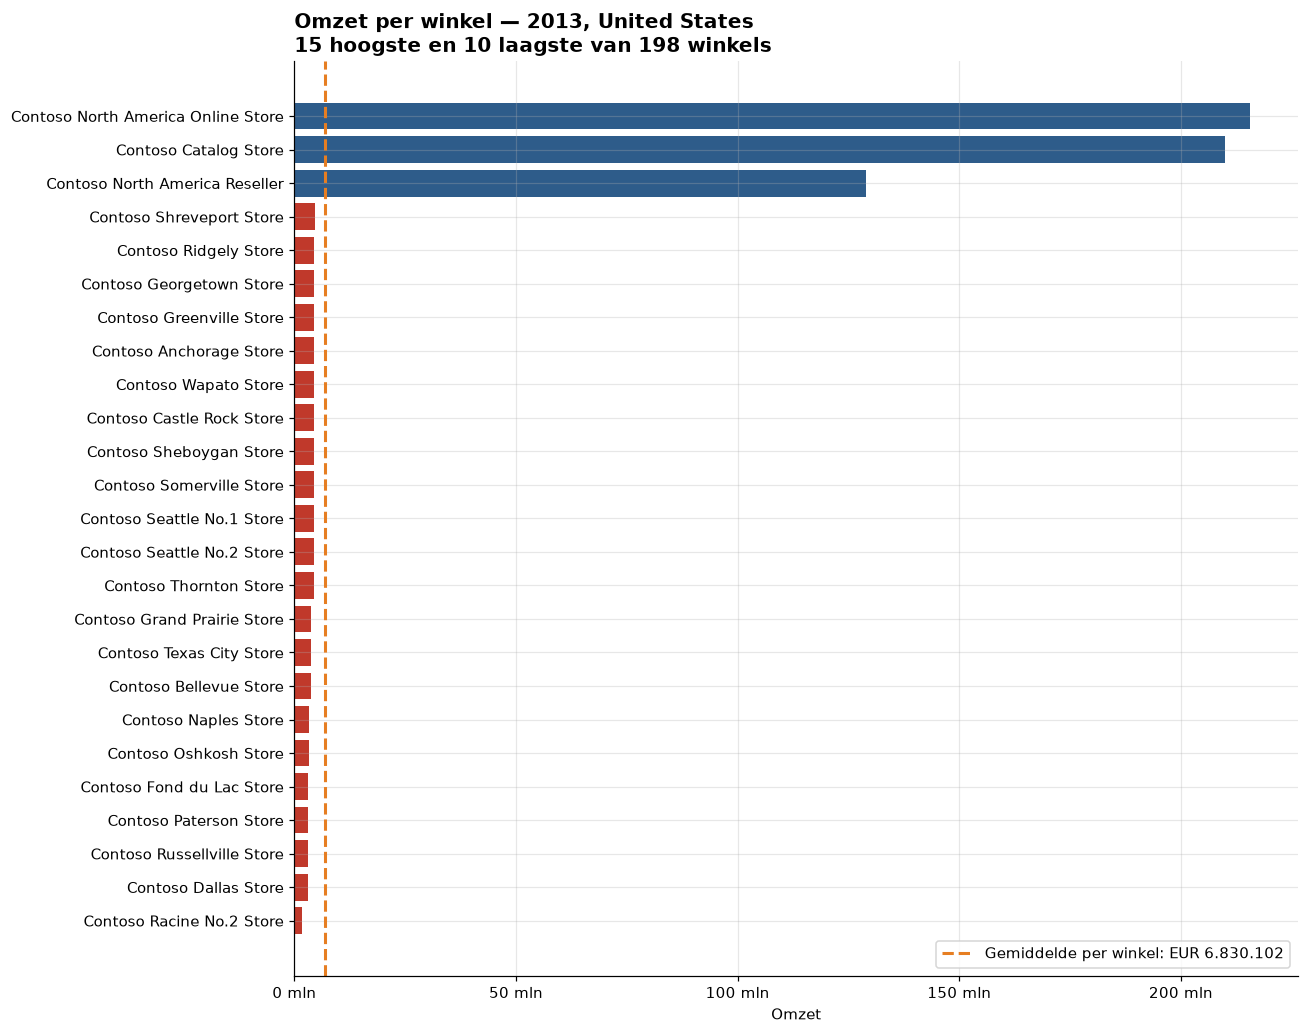

Winkels onder het gemiddelde: 195 van 198
StoreName
Contoso Racine No.2 Store            EUR 1.647.449
Contoso Dallas Store                 EUR 2.987.314
Contoso Russellville Store           EUR 2.997.468
Contoso Paterson Store               EUR 3.012.964
Contoso Fond du Lac Store            EUR 3.085.693
Contoso Oshkosh Store                EUR 3.207.460
Contoso Naples Store                 EUR 3.280.740
Contoso Bellevue Store               EUR 3.648.717
Contoso Texas City Store             EUR 3.770.905
Contoso Grand Prairie Store          EUR 3.777.382
Contoso Denver No.1 Store            EUR 3.786.376
Contoso Baltimore Store              EUR 3.829.400
Contoso Charleston Store             EUR 3.860.492
Contoso Hingham Store                EUR 3.876.990
Contoso Virginia Beach Store         EUR 3.888.310
Contoso Littleton Store              EUR 3.890.440
Contoso Bridgeport Store             EUR 3.890.985
Contoso Kennewick Store              EUR 3.893.663
Contoso Atlantic City Store   

In [199]:
selectie = filter_selectie(df, jaar=JAAR, kwartaal=KWARTAAL,
                           regio=REGIO, winkeltype=WINKELTYPE)
periode = beschrijf_periode(JAAR, KWARTAAL)

# SUM(Sales[SalesAmount]) met StoreName op de as.
omzet_per_winkel = (
    selectie.groupby("StoreName")["SalesAmount"].sum()
    .sort_values(ascending=False)
)

# Het gemiddelde over alle winkels in de selectie, niet alleen de getoonde.
gemiddelde = omzet_per_winkel.mean()
toon = top_en_bodem(omzet_per_winkel)

fig, ax = plt.subplots(figsize=(12, max(4, 0.32 * len(toon) + 1.5)))
kleuren = [ROOD if w < gemiddelde else BLAUW for w in toon.values]

ax.barh(toon.index, toon.values, color=kleuren)
ax.invert_yaxis()                      # hoogste omzet bovenaan
ax.axvline(gemiddelde, color=ORANJE, linestyle="--", linewidth=2,
           label=f"Gemiddelde per winkel: {euro(gemiddelde)}")

ondertitel = (f"alle {len(omzet_per_winkel)} winkels" if len(toon) == len(omzet_per_winkel)
              else f"15 hoogste en 10 laagste van {len(omzet_per_winkel)} winkels")
ax.set_title(f"Omzet per winkel — {periode}, {beschrijf_selectie(REGIO, WINKELTYPE)}\n{ondertitel}",
             fontsize=13, fontweight="bold", loc="left")
ax.set_xlabel("Omzet")
ax.set_ylabel("")
euro_as(ax, as_naam="x")
ax.legend(loc="lower right")

plt.tight_layout()
bewaar(fig, "us1_1_omzet_per_winkel")
plt.show()

onder = omzet_per_winkel[omzet_per_winkel < gemiddelde]
print(f"Winkels onder het gemiddelde: {len(onder)} van {len(omzet_per_winkel)}")
print(onder.sort_values().apply(euro).to_string())

### 5.2 US-1.2 — Omzet per vierkante meter

> *Als regiomanager wil ik de omzet per vierkante meter per winkel zien zodat ik
> winkels van verschillende grootte eerlijk met elkaar kan vergelijken en kan
> zien welke winkels hun vloeroppervlak inefficiënt benutten.*

**Visualisatie:** gegroepeerd staafdiagram met winkels op de y-as en omzet per m2
op de x-as, oplopend gesorteerd, met een referentielijn voor de gemiddelde omzet
per m2.

De absolute omzet van een winkel zegt weinig zonder de omvang ernaast: een grote
winkel haalt vanzelf meer omzet. Omzet per vierkante meter maakt winkels van
verschillende grootte vergelijkbaar. Oplopend sorteren zet de minst efficiënte
winkels bovenaan, want daar gaat de story over.

In Power BI is dit de measure `SalePerM2`, met een `CROSSFILTER` zodat alleen het
oppervlak van winkels met verkopen in de gekozen periode meetelt. In Python is
dat vanzelf zo: ik groepeer de *gefilterde* transacties per winkel, dus een
winkel zonder verkopen in de periode komt niet in de tabel voor.

Wel is er een valkuil. `SellingAreaSize` staat door de denormalisatie op elke
transactierij herhaald. Optellen zou het vloeroppervlak duizenden keren tellen.
Ik neem daarom per winkel de eerste waarde (`first`), niet de som.

opgeslagen: output/us1_2_omzet_per_m2.png


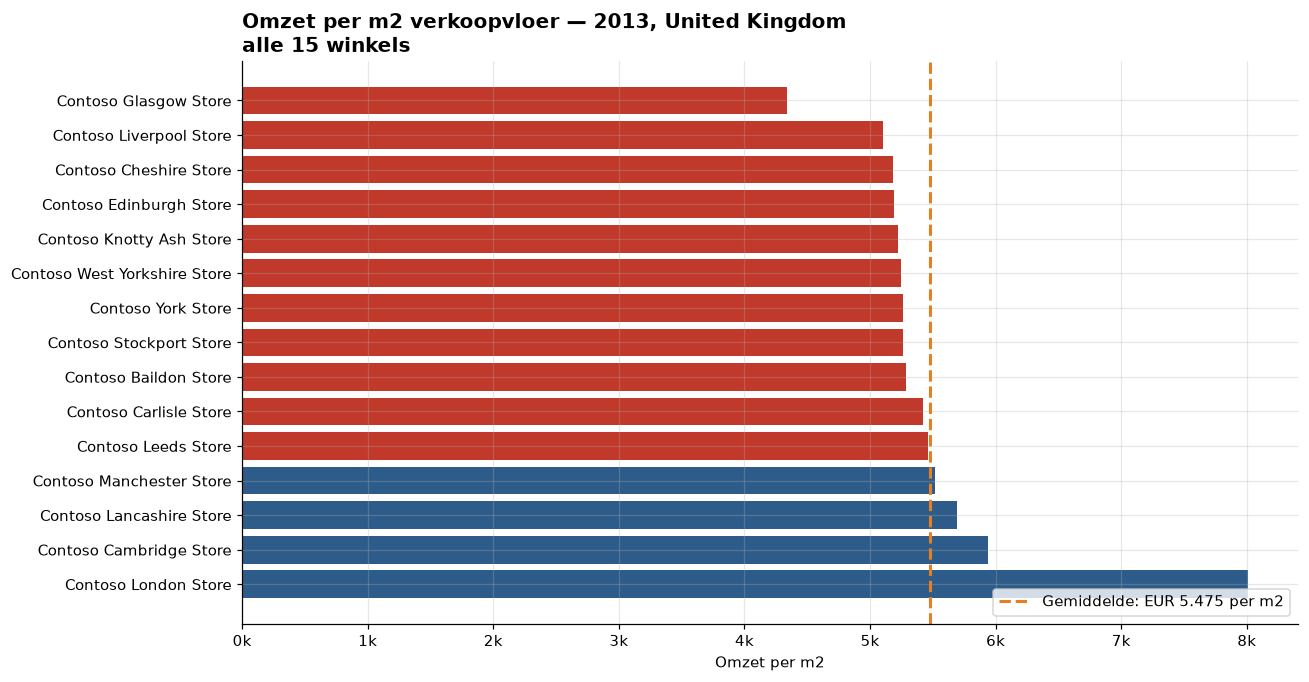

Winkels in de vergelijking: 15
Laagste: Contoso Glasgow Store — EUR 4.341 per m2
Hoogste: Contoso London Store — EUR 8.007 per m2


In [ ]:
selectie = filter_selectie(df, jaar=JAAR, kwartaal=KWARTAAL, regio=REGIO, winkeltype=WINKELTYPE)

periode = beschrijf_periode(JAAR, KWARTAAL)

per_m2 = selectie.groupby("StoreName").agg(
    Omzet=("SalesAmount", "sum"),
    Oppervlak=("SellingAreaSize", "first"),   # niet sum: de waarde is herhaald
)

# DIVIDE geeft in Power BI een lege waarde bij deling door nul; winkels zonder
# vloeroppervlak laat ik daarom weg.
per_m2 = per_m2[per_m2["Oppervlak"] > 0]
omzet_per_m2 = (per_m2["Omzet"] / per_m2["Oppervlak"]).sort_values()   # oplopend

gemiddelde_m2 = omzet_per_m2.mean()
toon = top_en_bodem(omzet_per_m2)

fig, ax = plt.subplots(figsize=(12, max(4, 0.32 * len(toon) + 1.5)))
kleuren = [ROOD if v < gemiddelde_m2 else BLAUW for v in toon.values]

ax.barh(toon.index, toon.values, color=kleuren)
ax.invert_yaxis()                      # laagste omzet per m2 bovenaan
ax.axvline(gemiddelde_m2, color=ORANJE, linestyle="--", linewidth=2,
           label=f"Gemiddelde: {euro(gemiddelde_m2)} per m2")

ondertitel = (f"alle {len(omzet_per_m2)} winkels" if len(toon) == len(omzet_per_m2)
              else f"15 laagste en 10 hoogste van {len(omzet_per_m2)} winkels")
ax.set_title(f"Omzet per m2 verkoopvloer — {periode}, {beschrijf_selectie(REGIO, WINKELTYPE)}\n{ondertitel}",
             fontsize=13, fontweight="bold", loc="left")
ax.set_xlabel("Omzet per m2")
ax.set_ylabel("")
euro_as(ax, as_naam="x", deler=1_000, achtervoegsel="k")
ax.legend(loc="lower right")

plt.tight_layout()
bewaar(fig, "us1_2_omzet_per_m2")
plt.show()

print(f"Winkels in de vergelijking: {len(omzet_per_m2)}")
print(f"Laagste: {omzet_per_m2.index[0]} — {euro(omzet_per_m2.iloc[0])} per m2")
print(f"Hoogste: {omzet_per_m2.index[-1]} — {euro(omzet_per_m2.iloc[-1])} per m2")

### 5.3 US-1.3 — Verloop van de omzet over de tijd

> *Als regiomanager wil ik het verloop van de omzet over de tijd zien, per jaar,
> kwartaal of maand, zodat ik seizoenspatronen en pieken of dalen kan herkennen
> en met filiaalmanagers de voorraad en personeel kan afstemmen.*

**Visualisatie:** lijndiagram over de volle breedte, met tijd op de x-as en omzet
op de y-as. Via de hiërarchie drilt de gebruiker van jaar naar kwartaal naar
maand. Bij selectie van één jaar toont de grafiek de maanden van dat jaar.

Een lijn is hier het juiste type omdat de perioden een doorlopende reeks vormen:
de vorm van de lijn laat seizoenspatroon en richting zien.

Python kent geen drill-down in een grafiek. Het hiërarchieniveau is daarom een
variabele: `NIVEAU` staat op `"jaar"`, `"kwartaal"` of `"maand"`.
`dt.to_period` zet elke datum om naar zijn periode (`Y`, `Q` of `M`), waarna
`groupby` de omzet per periode optelt. Ik gebruik bewust geen `resample`: dat
vult ontbrekende perioden aan met nul, zodat bij een kwartaalselectie over
meerdere jaren de lijn tussen de kwartalen naar nul zou zakken.
Staat `JAAR` op één jaar, dan schakelt de grafiek net als in Power BI naar de
maanden van dat jaar; de niveaus jaar en kwartaal zijn alleen bruikbaar met
`JAAR = None`. Met `KWARTAAL` beperk je de reeks tot één kwartaal; zonder jaarselectie zie je dan hetzelfde kwartaal in elk jaar naast
elkaar.

opgeslagen: output/us1_3_omzettrend.png


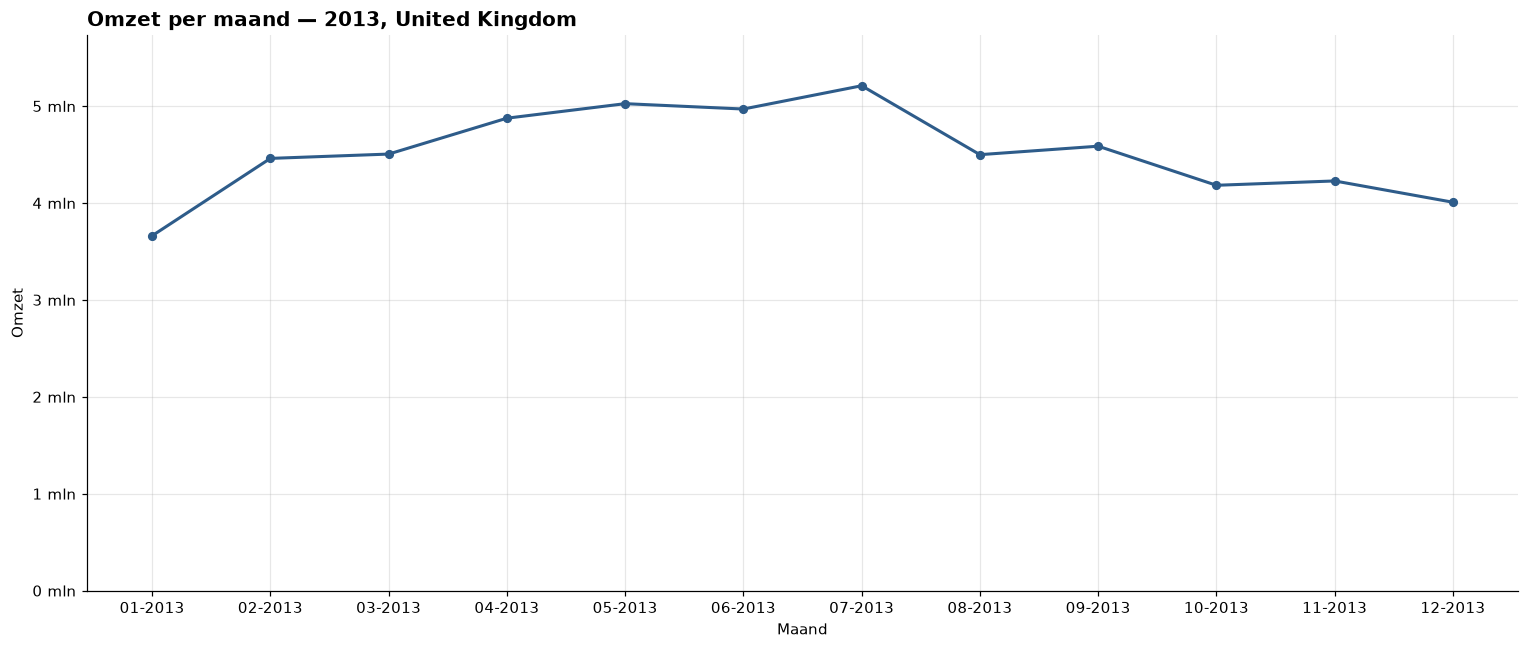

Hoogste maand: 07-2013 — EUR 5.209.482
Laagste maand: 01-2013 — EUR 3.661.655


In [186]:
NIVEAU = "maand"       # "jaar", "kwartaal" of "maand" — de drill-down
                       # (met één JAAR geselecteerd altijd "maand")

if JAAR is not None:
    NIVEAU = "maand"

selectie = filter_selectie(df, jaar=JAAR, kwartaal=KWARTAAL, regio=REGIO, winkeltype=WINKELTYPE)

frequentie = {"jaar": "Y", "kwartaal": "Q", "maand": "M"}[NIVEAU]

reeks = selectie.groupby(selectie["Datum"].dt.to_period(frequentie))["SalesAmount"].sum()

# Leesbare labels per hiërarchieniveau.
labels = {
    "jaar":     reeks.index.strftime("%Y"),
    "kwartaal": [f"{d.year} Q{d.quarter}" for d in reeks.index],
    "maand":    reeks.index.strftime("%m-%Y"),
}[NIVEAU]

fig, ax = plt.subplots(figsize=(14, 6))
posities = np.arange(len(reeks))
ax.plot(posities, reeks.values, color=BLAUW, linewidth=2, marker="o", markersize=5)

ax.set_xticks(posities)
ax.set_xticklabels(labels, rotation=45 if len(reeks) > 12 else 0,
                   ha="right" if len(reeks) > 12 else "center")

# Jaargrenzen markeren op maand- en kwartaalniveau.
if NIVEAU != "jaar":
    for i, periode in enumerate(reeks.index):
        if i > 0 and periode.year != reeks.index[i - 1].year:
            ax.axvline(i - 0.5, color=GRIJS, linewidth=1, alpha=0.6)

ax.set_title(f"Omzet per {NIVEAU} — {beschrijf_periode(JAAR, KWARTAAL)}, {beschrijf_selectie(REGIO, WINKELTYPE)}",
             fontsize=13, fontweight="bold", loc="left")
ax.set_xlabel(NIVEAU.capitalize())
ax.set_ylabel("Omzet")
ax.set_ylim(0, reeks.max() * 1.1)
euro_as(ax)

plt.tight_layout()
bewaar(fig, "us1_3_omzettrend")
plt.show()

print(f"Hoogste {NIVEAU}: {labels[int(reeks.values.argmax())]} — {euro(reeks.max())}")
print(f"Laagste {NIVEAU}: {labels[int(reeks.values.argmin())]} — {euro(reeks.min())}")

### 5.4 US-1.4 — Omzetgroei per winkel ten opzichte van vorig jaar

> *Als regiomanager wil ik in mijn regio per winkel de omzetgroei ten opzichte van vorig jaar
> zien zodat ik snel kan zien welke winkels groeien en welke krimpen, en gericht
> actie kan ondernemen bij krimpende winkels.*

**Visualisatie:** gegroepeerd staafdiagram met winkels op de y-as en
groeipercentage op de x-as, aflopend gesorteerd. Groei is groen, daling rood.
Werkt alleen als precies één jaar is geselecteerd en het jaar ervoor omzet heeft.

In Power BI is dit de measure `ComparisonToLastYear`, die met
`SAMEPERIODLASTYEAR` de omzet van dezelfde periode vorig jaar ophaalt en het
verschil deelt door dat vorige jaar. Python kent geen time intelligence. Ik tel
de omzet per winkel daarom apart op voor het gekozen jaar en het jaar ervoor,
en deel het verschil door het vorige jaar. Omdat beide reeksen de winkelnaam als
index hebben, rekent pandas per winkel: de omzet van winkel A wordt nooit met die
van winkel B vergeleken. Een winkel zonder omzet in het vorige jaar krijgt geen
groeicijfer, net als `DIVIDE` in Power BI dan leeg blijft.

Met `KWARTAAL` vergelijk je één kwartaal met hetzelfde kwartaal een jaar
eerder, wat `SAMEPERIODLASTYEAR` in Power BI ook doet. De regio- en
winkeltypeslicer gelden voor beide jaren, zodat dezelfde winkels met zichzelf
worden vergeleken. Met `REGIO = None` gaat de vergelijking over alle ruim 300
winkels; dan toon ik de vijftien sterkste stijgers en tien sterkste dalers.

opgeslagen: output/us1_4_groei_per_winkel.png


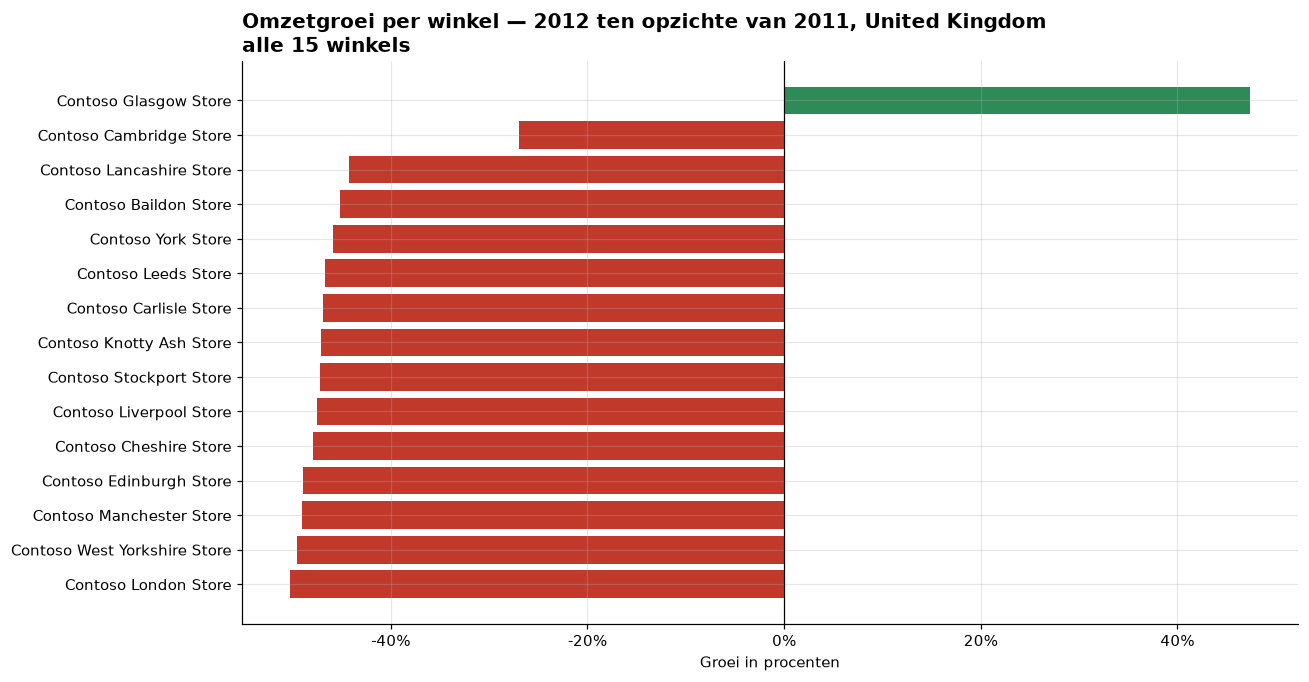

Winkels met groei: 1
Winkels met krimp: 14
Totale groei 2012: -43.9%


In [197]:
# Dezelfde voorwaarden als in Power BI: precies één jaar geselecteerd, en het
# jaar ervoor moet omzet hebben.
if not isinstance(JAAR, int):
    raise ValueError("US-1.4 vereist precies één jaar: zet JAAR bovenaan tabblad 1.")
if JAAR - 1 not in df["Year"].unique():
    raise ValueError(f"Geen omzet in {JAAR - 1}; kies een jaar vanaf "
                     f"{df['Year'].min() + 1}.")

huidig = (filter_selectie(df, jaar=JAAR, kwartaal=KWARTAAL,
                          regio=REGIO, winkeltype=WINKELTYPE)
          .groupby("StoreName")["SalesAmount"].sum())
vorig = (filter_selectie(df, jaar=JAAR - 1, kwartaal=KWARTAAL,
                         regio=REGIO, winkeltype=WINKELTYPE)
         .groupby("StoreName")["SalesAmount"].sum())

groei = ((huidig - vorig) / vorig).dropna().sort_values(ascending=False)
toon = top_en_bodem(groei)

fig, ax = plt.subplots(figsize=(12, max(4, 0.32 * len(toon) + 1.5)))

# Voorwaardelijke opmaak: groei groen, krimp rood. Dit is hetzelfde als de
# regelgebaseerde voorwaardelijke opmaak in Power BI.
kleuren = np.where(toon.values >= 0, GROEN, ROOD)

ax.barh(toon.index, toon.values * 100, color=kleuren)
ax.invert_yaxis()                      # sterkste groei bovenaan
ax.axvline(0, color="black", linewidth=0.8)

ondertitel = (f"alle {len(groei)} winkels" if len(toon) == len(groei)
              else f"15 sterkste stijgers en 10 sterkste dalers van {len(groei)} winkels")
ax.set_title(f"Omzetgroei per winkel — {beschrijf_periode(JAAR, KWARTAAL)} "
             f"ten opzichte van {beschrijf_periode(JAAR - 1, KWARTAAL)}, "
             f"{beschrijf_selectie(REGIO, WINKELTYPE)}\n{ondertitel}",
             fontsize=13, fontweight="bold", loc="left")
ax.set_xlabel("Groei in procenten")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:.0f}%"))

plt.tight_layout()
bewaar(fig, "us1_4_groei_per_winkel")
plt.show()

print(f"Winkels met groei: {(groei >= 0).sum()}")
print(f"Winkels met krimp: {(groei < 0).sum()}")
print(f"Totale groei {beschrijf_periode(JAAR, KWARTAAL)}: {(huidig.sum() / vorig.sum() - 1) * 100:+.1f}%")

### 5.5 US-1.5 — Omzet per productcategorie binnen de regio

> *Als regiomanager wil ik de omzet per productcategorie binnen mijn regio zien
> zodat ik weet welke categorieën de meeste omzet opleveren en waar ik het
> assortiment of de promotie kan aanpassen.*

**Visualisatie:** gegroepeerd kolomdiagram met productcategorieën op de x-as en
omzet op de y-as, aflopend gesorteerd.

Aflopend sorteren zet de belangrijkste categorie links, zodat de rangorde direct
leesbaar is. Boven elke kolom staat het aandeel in de omzet van de regio; dat
maakt het verschil tussen een grote en een kleine categorie concreet.

De categorie komt uit de sub-dimensie `ProductCategory`, die via
`ProductSubcategory` aan de feitentabel hangt. Volgens de story zijn een jaar en
een regio verplicht. De code controleert dat en stopt met een duidelijke
melding als `JAAR` of `REGIO` op `None` of een lijst staat. Kwartaal en
winkeltype zijn optioneel, net als bij de andere visualisaties van dit tabblad.

opgeslagen: output/us1_5_omzet_per_categorie.png


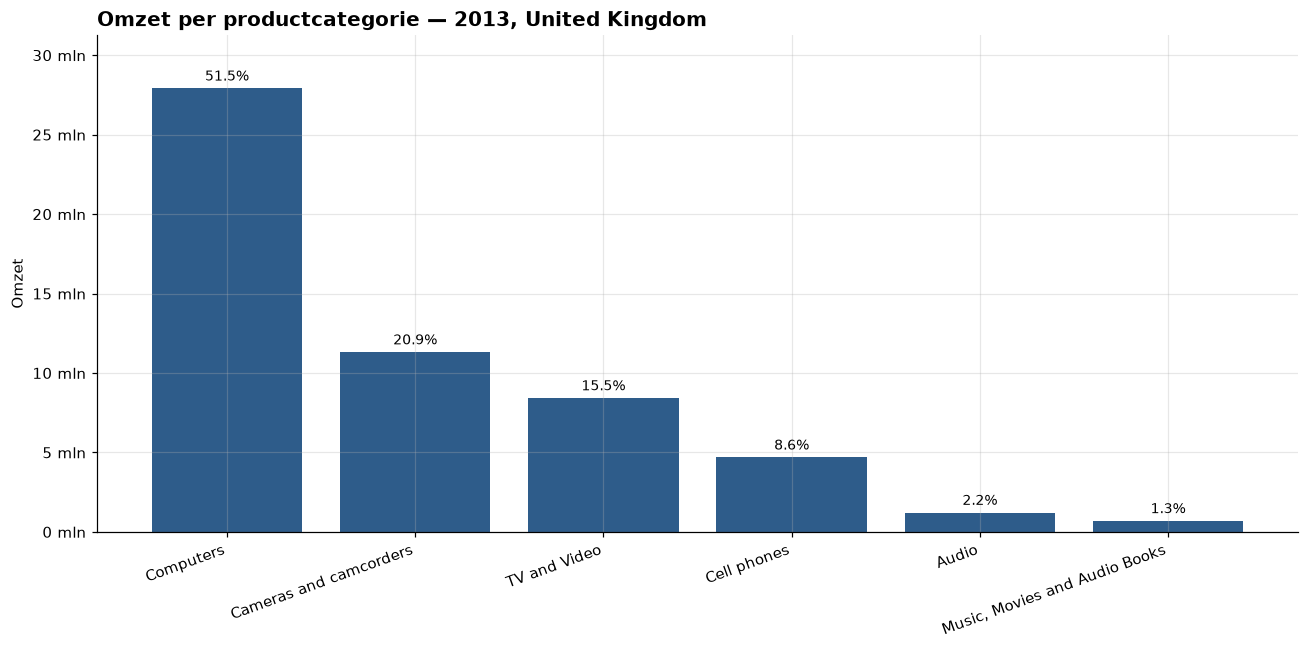

                                        Omzet Aandeel
ProductCategoryName                                  
Computers                      EUR 27.907.993   51.5%
Cameras and camcorders         EUR 11.307.230   20.9%
TV and Video                    EUR 8.415.829   15.5%
Cell phones                     EUR 4.683.492    8.6%
Audio                           EUR 1.206.940    2.2%
Music, Movies and Audio Books     EUR 683.666    1.3%


In [188]:
# De story vraagt precies één jaar en één regio.
if not isinstance(JAAR, int):
    raise ValueError("US-1.5 vereist precies één jaar: zet JAAR bovenaan tabblad 1.")
if not isinstance(REGIO, str):
    raise ValueError("US-1.5 vereist precies één regio: zet REGIO bovenaan tabblad 1.")

selectie = filter_selectie(df, jaar=JAAR, kwartaal=KWARTAAL,
                           regio=REGIO, winkeltype=WINKELTYPE)

per_categorie = (
    selectie.groupby("ProductCategoryName")["SalesAmount"].sum()
    .sort_values(ascending=False)
)
aandeel = per_categorie / per_categorie.sum()

fig, ax = plt.subplots(figsize=(12, 6))
balken = ax.bar(per_categorie.index, per_categorie.values, color=BLAUW)
ax.bar_label(balken, labels=[f"{a:.1%}" for a in aandeel], padding=3, fontsize=9)

ax.set_title(f"Omzet per productcategorie — {beschrijf_periode(JAAR, KWARTAAL)}, "
             f"{beschrijf_selectie(REGIO, WINKELTYPE)}",
             fontsize=13, fontweight="bold", loc="left")
ax.set_xlabel("")
ax.set_ylabel("Omzet")
ax.set_ylim(0, per_categorie.max() * 1.12)
ax.tick_params(axis="x", labelrotation=20)
plt.setp(ax.get_xticklabels(), ha="right")
euro_as(ax)

plt.tight_layout()
bewaar(fig, "us1_5_omzet_per_categorie")
plt.show()

print(pd.DataFrame({"Omzet": per_categorie.apply(euro),
                    "Aandeel": aandeel.apply(lambda x: f"{x:.1%}")}).to_string())

## 6. Visualisaties tabblad 2 — Marketingmanager

Het tweede dashboardtabblad richt zich op de vraag wanneer, via welk kanaal en
met welke promotie de omzet tot stand komt. Hier komt de eigen dataset met
feestdagen in beeld.

De slicers van dit tabblad staan samen in de cel hieronder: jaar, kwartaal,
regio en winkeltype. Kwartaal, regio en winkeltype gelden voor alle vijf
visualisaties. De jaarslicer werkt alleen op US-2.1: US-2.2 tot en met US-2.5
zetten de jaren naast elkaar, en met één jaar geselecteerd valt er in die
grafieken niets meer te vergelijken. Met `KWARTAAL_MARKETING` vergelijk je daar
wel hetzelfde kwartaal over de jaren, bijvoorbeeld Q4 met de feestdagen aan het
eind van het jaar.

De feestdagendimensie
bevat alleen Amerikaanse feestdagen (hoofdstuk 3), dus staat de regio standaard
op de Verenigde Staten. Zonder dat filter zouden Europese verkopen op
bijvoorbeeld Thanksgiving als feestdagomzet meetellen, terwijl die dag daar geen
feestdag is.

Voor de promotiegrafieken (US-2.4 en US-2.5) leg ik hier ook één kleur per
promotie vast, zodat dezelfde promotie in beide grafieken dezelfde kleur heeft.

In [189]:
# Slicers van tabblad 2. None = geen selectie (alles).
JAAR_MARKETING = None                 # Contoso_Calendar[Year]: 2011, 2012 of 2013 (alleen US-2.1)
KWARTAAL_MARKETING = None             # Contoso_Calendar[QuarterOfYear]: 1, 2, 3 of 4
REGIO_MARKETING = "United States"     # Contoso_Geography[RegionCountryName]
WINKELTYPE_MARKETING = None           # Contoso_Stores[StoreType]: Store, Online, Catalog of Reseller

if REGIO_MARKETING != "United States":
    print("Let op: de feestdagendimensie bevat alleen Amerikaanse feestdagen. "
          "US-2.1 en US-2.2 zijn buiten de Verenigde Staten niet betrouwbaar.\n")

# Vaste kleur per promotie: "No Discount" grijs als referentie, de promoties
# uit de tab10-reeks (zonder de grijstint daarin).
promoties = sorted(p for p in df["PromotionName"].unique() if p != "No Discount")
tab10 = [c for i, c in enumerate(plt.cm.tab10.colors) if i != 7]
PROMOTIE_KLEUR = {"No Discount": GRIJS} | {
    p: tab10[i % len(tab10)] for i, p in enumerate(promoties)
}

print(f"Gekozen selectie: {beschrijf_periode(JAAR_MARKETING, KWARTAAL_MARKETING)} (jaar alleen voor US-2.1), "
      f"{beschrijf_selectie(REGIO_MARKETING, WINKELTYPE_MARKETING)}")
print(f"Promoties: {len(promoties)} plus No Discount")

Gekozen selectie: United States
Promoties: 9 plus No Discount


### 6.1 US-2.1 — Gemiddelde aankoopwaarde per feestdag

> *Als marketingmanager wil ik de gemiddelde aankoopwaarde per feestdag
> vergelijken met die op normale dagen zodat ik weet op welke feestdagen klanten
> het meest besteden en daar campagnes op kan plannen.*

**Visualisatie:** gegroepeerd kolomdiagram met feestdagen op de x-as en gemiddelde
aankoopwaarde op de y-as, aflopend gesorteerd, met gegevenslabels. Een
referentielijn toont het gemiddelde. "Geen feestdag" is als aparte kolom
opgenomen ter vergelijking.

De vergelijking kan niet met de *totale* omzet: over 2011-2013 staan 1.063
normale dagen tegenover 33 feestdagen, dus elke optelling valt vanzelf in het
voordeel van de normale dagen uit. De gemiddelde aankoopwaarde (het gemiddelde
`SalesAmount` per transactie) is wel eerlijk te vergelijken, omdat die niet
afhangt van het aantal dagen.

De lege waarden voor dagen zonder feestdag zijn in hoofdstuk 3 al ingevuld als
"Geen feestdag", net als in Power Query. Die kolom krijgt een grijze kleur, zodat
hij als referentie herkenbaar is.

opgeslagen: output/us2_1_aankoopwaarde_per_feestdag.png


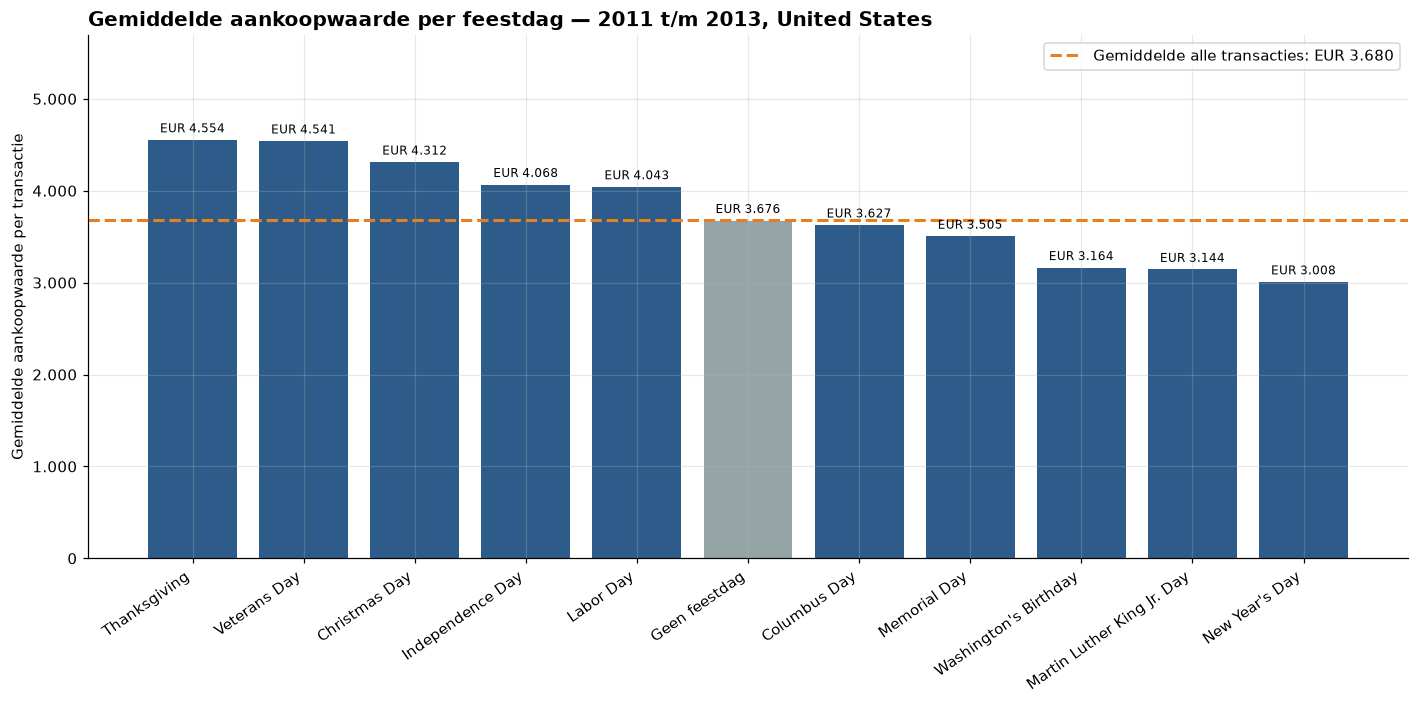

FeestdagNaam
Thanksgiving                  +23.9% t.o.v. geen feestdag
Veterans Day                  +23.5% t.o.v. geen feestdag
Christmas Day                 +17.3% t.o.v. geen feestdag
Independence Day              +10.7% t.o.v. geen feestdag
Labor Day                     +10.0% t.o.v. geen feestdag
Columbus Day                   -1.3% t.o.v. geen feestdag
Memorial Day                   -4.7% t.o.v. geen feestdag
Washington's Birthday         -13.9% t.o.v. geen feestdag
Martin Luther King Jr. Day    -14.5% t.o.v. geen feestdag
New Year's Day                -18.2% t.o.v. geen feestdag


In [190]:
selectie = filter_selectie(df, jaar=JAAR_MARKETING, kwartaal=KWARTAAL_MARKETING,
                           regio=REGIO_MARKETING, winkeltype=WINKELTYPE_MARKETING)

per_feestdag = (
    selectie.groupby("FeestdagNaam")["SalesAmount"].mean()
    .sort_values(ascending=False)
)
gemiddelde = selectie["SalesAmount"].mean()

fig, ax = plt.subplots(figsize=(13, 6.5))
kleuren = [GRIJS if naam == "Geen feestdag" else BLAUW for naam in per_feestdag.index]
balken = ax.bar(per_feestdag.index, per_feestdag.values, color=kleuren)
ax.bar_label(balken, labels=[euro(v) for v in per_feestdag.values], padding=3, fontsize=8)
ax.axhline(gemiddelde, color=ORANJE, linestyle="--", linewidth=2,
           label=f"Gemiddelde alle transacties: {euro(gemiddelde)}")

ax.set_title(f"Gemiddelde aankoopwaarde per feestdag — {beschrijf_periode(JAAR_MARKETING, KWARTAAL_MARKETING)}, "
             f"{beschrijf_selectie(REGIO_MARKETING, WINKELTYPE_MARKETING)}",
             fontsize=13, fontweight="bold", loc="left")
ax.set_xlabel("")
ax.set_ylabel("Gemiddelde aankoopwaarde per transactie")
ax.set_ylim(0, per_feestdag.max() * 1.25)
ax.tick_params(axis="x", labelrotation=35)
plt.setp(ax.get_xticklabels(), ha="right")
euro_as(ax, deler=1, achtervoegsel="")
ax.legend(loc="upper right")

plt.tight_layout()
bewaar(fig, "us2_1_aankoopwaarde_per_feestdag")
plt.show()

normaal = per_feestdag["Geen feestdag"]
print((per_feestdag / normaal - 1).drop("Geen feestdag")
      .apply(lambda x: f"{x:+.1%} t.o.v. geen feestdag").to_string())

### 6.2 US-2.2 — Feestdag versus normale dag per jaar

> *Als marketingmanager wil ik per jaar de gemiddelde aankoopwaarde op
> feestdagen vergelijken met die van normale dagen zodat ik kan zien of het
> effect van campagnes voor feestdagen door de jaren heen groter of kleiner
> wordt.*

**Visualisatie:** gegroepeerd kolomdiagram met jaar op de x-as en gemiddelde
aankoopwaarde op de y-as. De legenda splitst in feestdag en normale dag, met
gegevenslabels.

Waar US-2.1 per feestdag kijkt, kijkt deze grafiek naar de ontwikkeling. Twee
kolommen naast elkaar per jaar maken het verschil binnen een jaar én de trend
over de jaren zichtbaar.

In Power BI staat `IsFeestdag` in de legenda. Hier gebruik ik de kolom `DagType`
uit dezelfde dimensie: die bevat dezelfde indeling, maar met de leesbare labels
"Feestdag" en "Normale dag" in plaats van True en False.

opgeslagen: output/us2_2_feestdag_per_jaar.png


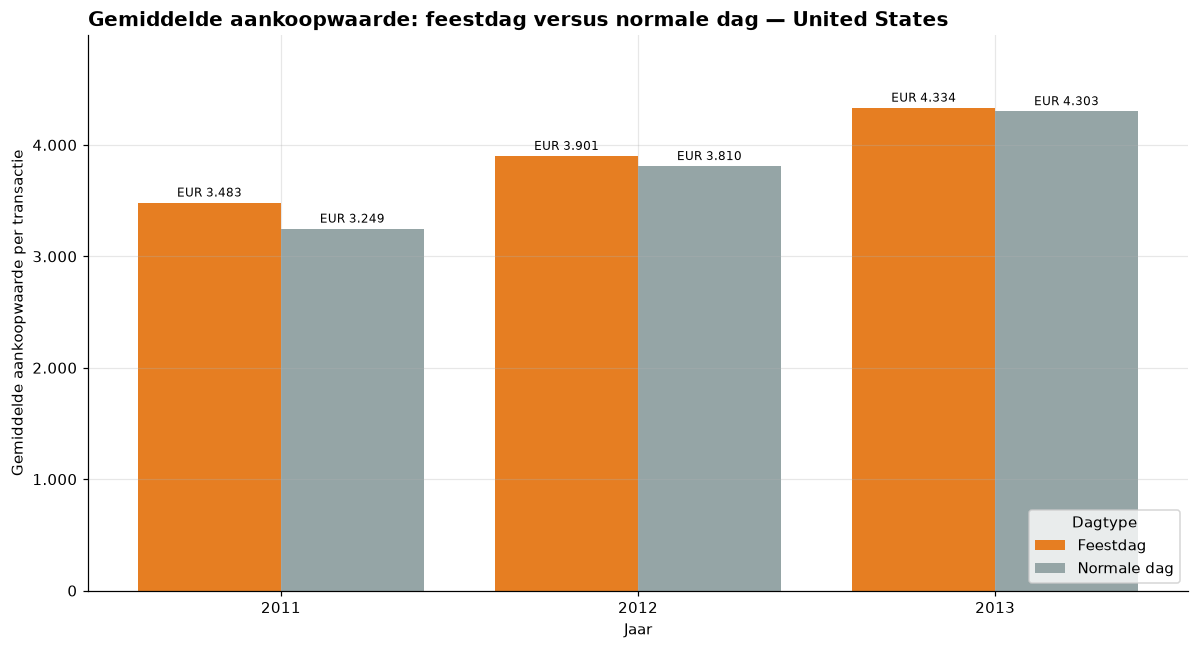

Verschil feestdag ten opzichte van normale dag:
Year
2011    +7.2%
2012    +2.4%
2013    +0.7%


In [191]:
selectie = filter_selectie(df, kwartaal=KWARTAAL_MARKETING,
                           regio=REGIO_MARKETING, winkeltype=WINKELTYPE_MARKETING)

per_jaar = selectie.pivot_table(
    index="Year",
    columns="DagType",
    values="SalesAmount",
    aggfunc="mean",
)[["Feestdag", "Normale dag"]]

fig, ax = plt.subplots(figsize=(11, 6))
gegroepeerde_kolommen(ax, per_jaar, [ORANJE, GRIJS], label_opmaak=euro)

ax.set_title(f"Gemiddelde aankoopwaarde: feestdag versus normale dag — "
             f"{beschrijf_periode(kwartaal=KWARTAAL_MARKETING)}, {beschrijf_selectie(REGIO_MARKETING, WINKELTYPE_MARKETING)}",
             fontsize=13, fontweight="bold", loc="left")
ax.set_xlabel("Jaar")
ax.set_ylabel("Gemiddelde aankoopwaarde per transactie")
ax.set_ylim(0, per_jaar.max().max() * 1.15)
euro_as(ax, deler=1, achtervoegsel="")
ax.legend(title="Dagtype", loc="lower right")

plt.tight_layout()
bewaar(fig, "us2_2_feestdag_per_jaar")
plt.show()

verschil = per_jaar["Feestdag"] / per_jaar["Normale dag"] - 1
print("Verschil feestdag ten opzichte van normale dag:")
print(verschil.apply(lambda x: f"{x:+.1%}").to_string())

### 6.3 US-2.3 — Omzet per verkoopkanaal per jaar

> *Als marketingmanager wil ik de omzet per verkoopkanaal per jaar zien zodat ik
> weet welke kanalen het belangrijkst zijn en waar ik het marketingbudget het
> beste kan inzetten.*

**Visualisatie:** gegroepeerd kolomdiagram met jaar op de x-as en omzet op de
y-as. De legenda splitst per kanaal: Catalog, Online, Reseller en Store.

Met het jaar op de x-as en de kanalen naast elkaar is zowel de verhouding tussen
kanalen als de ontwikkeling per kanaal te zien. `pivot_table` zet de jaren in de
rijen en de kanalen in de kolommen; dat is het formaat dat
`gegroepeerde_kolommen` nodig heeft.

`ChannelName` is in Power BI ook een slicer. Hier is dat `KANAAL`: `None` voor
alle kanalen, of een lijst zoals `["Online", "Store"]`. Omdat deze slicer alleen
bij deze visualisatie hoort, staat hij boven de cel en niet bij de slicers van
het tabblad.

opgeslagen: output/us2_3_omzet_per_kanaal.png


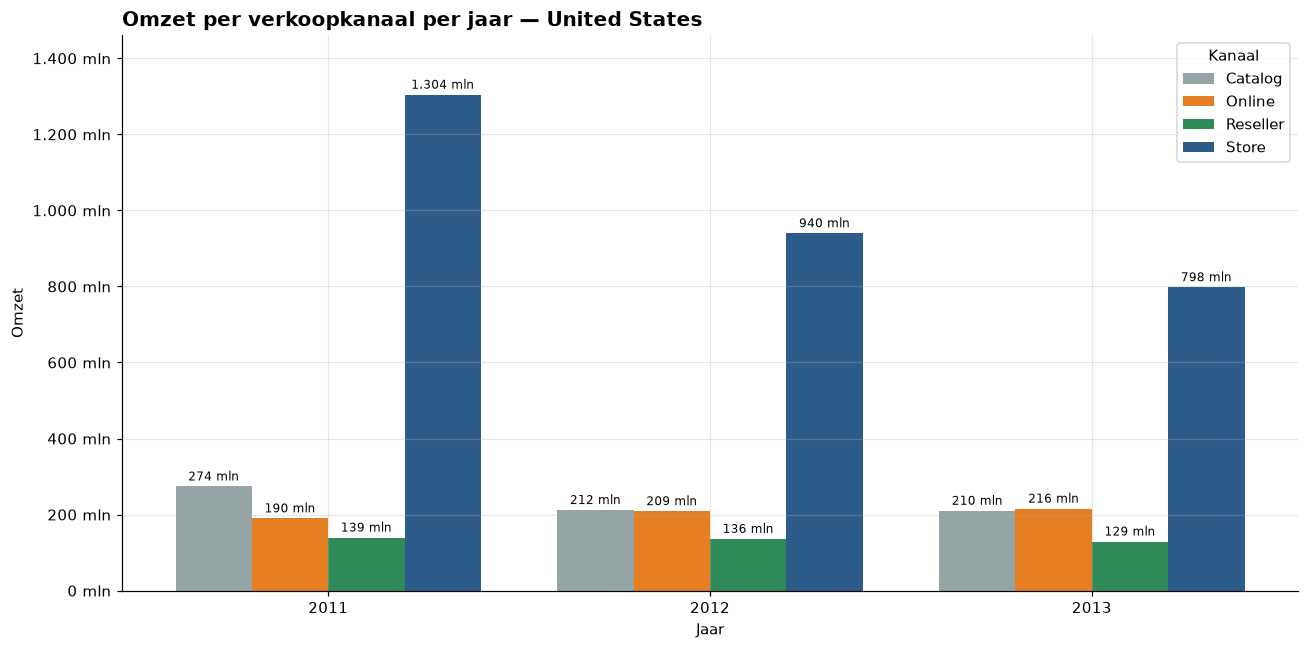

Aandeel per kanaal per jaar:
ChannelName Catalog Online Reseller  Store
Year                                      
2011          14.4%  10.0%     7.3%  68.4%
2012          14.2%  14.0%     9.1%  62.8%
2013          15.5%  15.9%     9.5%  59.0%


In [192]:
KANAAL = None          # None = alle kanalen, of bijvoorbeeld ["Online", "Store"]

selectie = filter_selectie(df, kwartaal=KWARTAAL_MARKETING,
                           regio=REGIO_MARKETING, winkeltype=WINKELTYPE_MARKETING,
                           kanaal=KANAAL)

kanaal_jaar = selectie.pivot_table(
    index="Year",
    columns="ChannelName",
    values="SalesAmount",
    aggfunc="sum",
)
# Vaste volgorde uit de user story.
kanaal_jaar = kanaal_jaar[[k for k in ["Catalog", "Online", "Reseller", "Store"]
                           if k in kanaal_jaar.columns]]

fig, ax = plt.subplots(figsize=(12, 6))
gegroepeerde_kolommen(ax, kanaal_jaar, [GRIJS, ORANJE, GROEN, BLAUW],
                      label_opmaak=lambda v: f"{v / 1_000_000:,.0f} mln".replace(",", "."))

ax.set_title(f"Omzet per verkoopkanaal per jaar — {beschrijf_periode(kwartaal=KWARTAAL_MARKETING)}, {beschrijf_selectie(REGIO_MARKETING, WINKELTYPE_MARKETING)}",
             fontsize=13, fontweight="bold", loc="left")
ax.set_xlabel("Jaar")
ax.set_ylabel("Omzet")
ax.set_ylim(0, kanaal_jaar.max().max() * 1.12)
euro_as(ax)
ax.legend(title="Kanaal")

plt.tight_layout()
bewaar(fig, "us2_3_omzet_per_kanaal")
plt.show()

aandeel = kanaal_jaar.div(kanaal_jaar.sum(axis=1), axis=0)
print("Aandeel per kanaal per jaar:")
print(aandeel.map(lambda x: f"{x:.1%}").to_string())

### 6.4 US-2.4 — Aandeel van promoties in de omzet over de jaren

> *Als marketingmanager wil ik het relatieve aandeel van elke promotie, en van
> verkopen zonder korting, in de totale omzet over de jaren zien zodat ik kan
> signaleren of onze omzet steeds afhankelijker wordt van promoties en tijdig
> kan bijsturen om onze marge te beschermen.*

**Visualisatie:** 100%-gestapeld vlakdiagram met jaar op de x-as en omzetaandeel
op de y-as. De legenda splitst per promotie, inclusief "No Discount".

Een 100%-gestapeld vlak laat de verhouding zien los van de groei of krimp van het
totaal: wordt de grijze band "No Discount" smaller, dan wordt de omzet
afhankelijker van promoties. "No Discount" ligt daarom onderaan als basis.

In de promotietabel komt dezelfde promotienaam meerdere keren voor, met per jaar
een eigen `PromotionKey`. Door te groeperen op `PromotionName` worden die
samengevoegd, net als in de Power BI-legenda. `stackplot` stapelt de kolommen
van de tabel; na het delen door het jaartotaal tellen ze per jaar op tot 100%.

opgeslagen: output/us2_4_aandeel_promoties.png


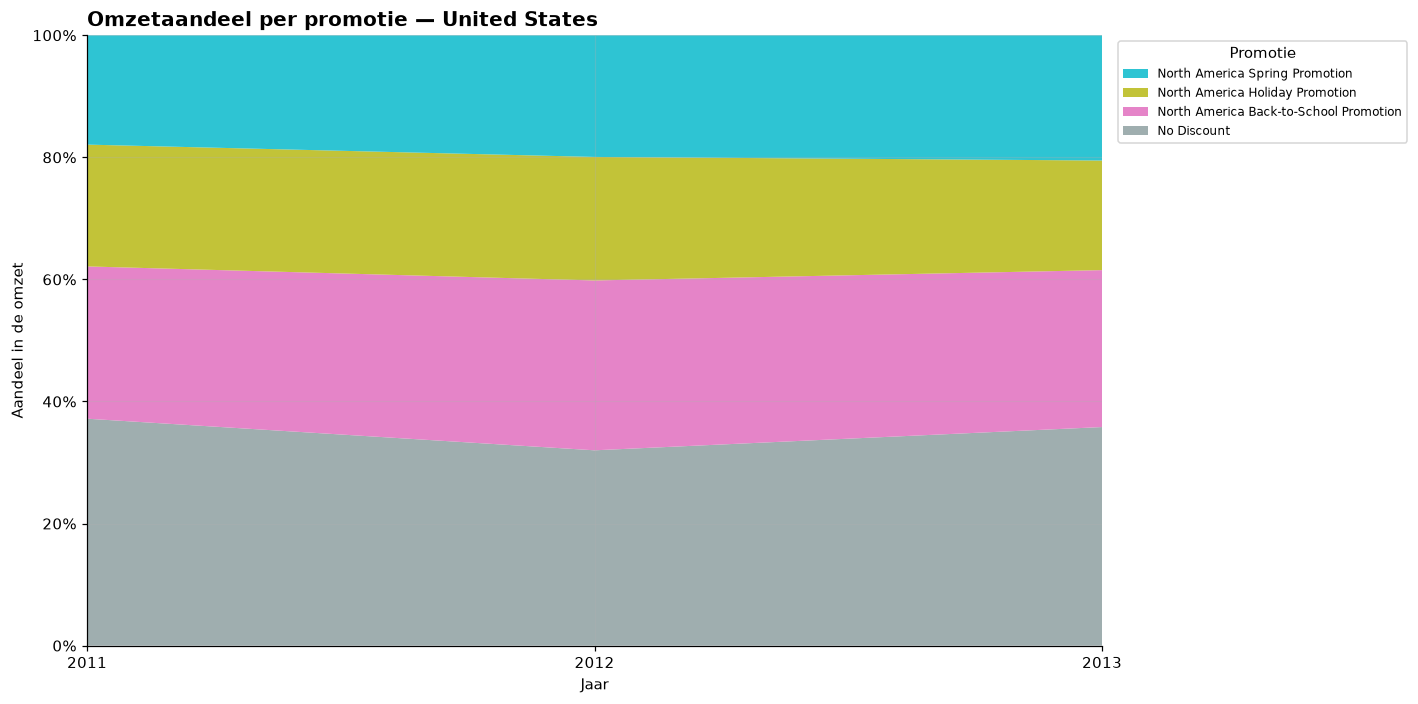

Year                                    2011  2012  2013
PromotionName                                           
No Discount                            37.20 32.00 35.80
North America Back-to-School Promotion 24.90 27.80 25.70
North America Holiday Promotion        20.00 20.20 18.00
North America Spring Promotion         17.90 19.90 20.50


In [193]:
selectie = filter_selectie(df, kwartaal=KWARTAAL_MARKETING,
                           regio=REGIO_MARKETING, winkeltype=WINKELTYPE_MARKETING)

promotie_jaar = selectie.pivot_table(
    index="Year",
    columns="PromotionName",
    values="SalesAmount",
    aggfunc="sum",
).fillna(0)

# No Discount onderaan, daarna de promoties van groot naar klein.
volgorde = ["No Discount"] + [p for p in promotie_jaar.sum().sort_values(ascending=False).index
                              if p != "No Discount"]
aandeel = promotie_jaar[volgorde].div(promotie_jaar.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(13, 6.5))
ax.stackplot(aandeel.index, aandeel.T.values, labels=aandeel.columns,
             colors=[PROMOTIE_KLEUR[p] for p in aandeel.columns], alpha=0.9)

ax.set_title(f"Omzetaandeel per promotie — {beschrijf_periode(kwartaal=KWARTAAL_MARKETING)}, {beschrijf_selectie(REGIO_MARKETING, WINKELTYPE_MARKETING)}",
             fontsize=13, fontweight="bold", loc="left")
ax.set_xlabel("Jaar")
ax.set_ylabel("Aandeel in de omzet")
ax.set_xticks(aandeel.index)
ax.set_ylim(0, 100)
ax.margins(x=0)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:.0f}%"))

# Legenda in dezelfde volgorde als de stapel: bovenste band bovenaan.
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], title="Promotie", fontsize=8,
          loc="upper left", bbox_to_anchor=(1.01, 1))

plt.tight_layout()
bewaar(fig, "us2_4_aandeel_promoties")
plt.show()

print(aandeel.T.round(1).to_string())

### 6.5 US-2.5 — Totale omzet per promotie per jaar

> *Als marketingmanager wil ik de totale omzet per promotie per jaar zien zodat
> ik kan bepalen welke promoties de meeste omzet opleveren en welke ik moet
> herhalen of stopzetten.*

**Visualisatie:** gegroepeerd kolomdiagram met jaar op de x-as en omzet op de
y-as. De legenda splitst per promotie, inclusief "No Discount" als referentie.

Waar US-2.4 de verhouding toont, toont deze grafiek de absolute bedragen. Een
promotie met een gelijk aandeel kan in euro's toch zijn gedaald als de totale
omzet daalt; daarom staan beide grafieken op het dashboard. De kleuren zijn
dezelfde als in US-2.4.

opgeslagen: output/us2_5_omzet_per_promotie.png


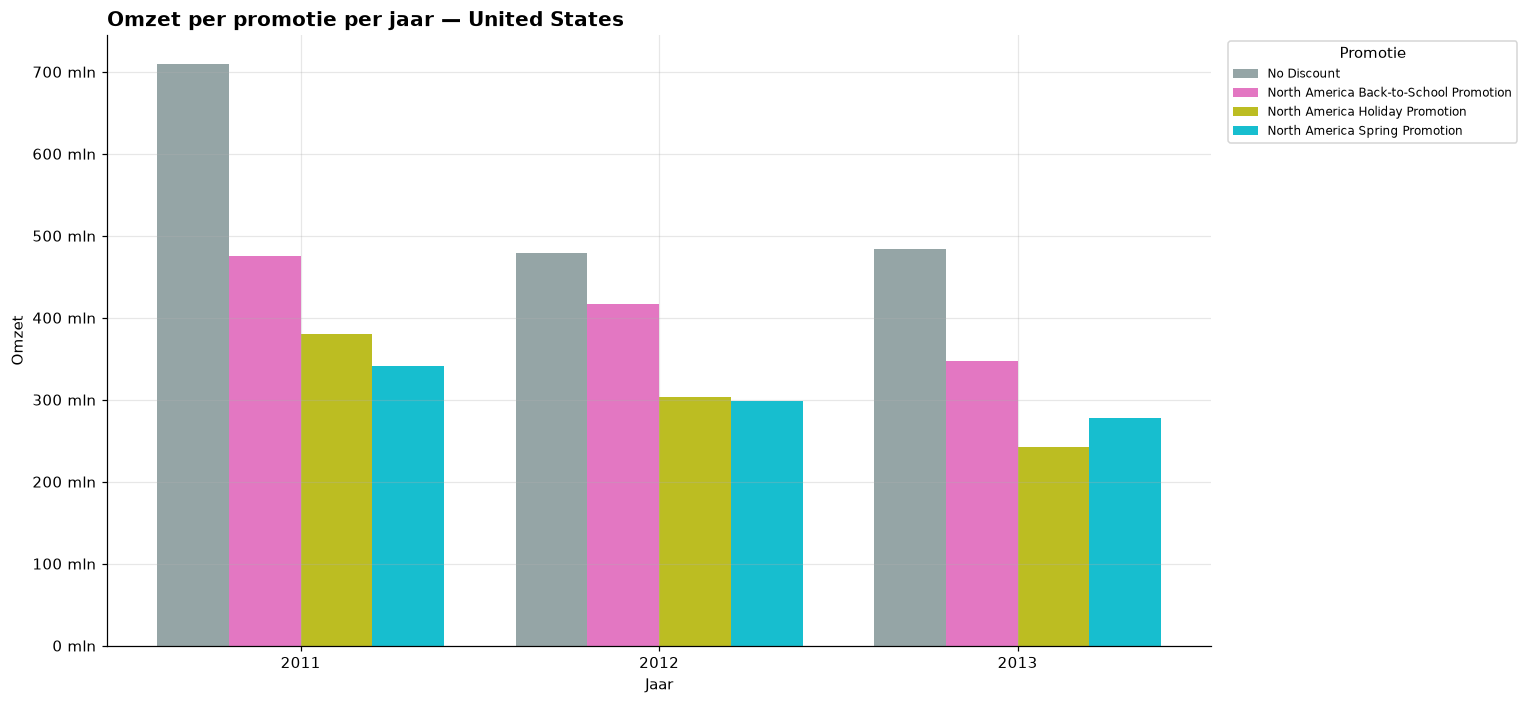

Omzet per promotie in miljoenen:
Year                                     2011   2012   2013
PromotionName                                              
No Discount                            709.10 479.00 484.30
North America Back-to-School Promotion 475.90 416.50 347.70
North America Holiday Promotion        380.60 302.90 242.80
North America Spring Promotion         341.70 298.40 277.50


In [194]:
selectie = filter_selectie(df, kwartaal=KWARTAAL_MARKETING,
                           regio=REGIO_MARKETING, winkeltype=WINKELTYPE_MARKETING)

promotie_jaar = selectie.pivot_table(
    index="Year",
    columns="PromotionName",
    values="SalesAmount",
    aggfunc="sum",
)

# No Discount als referentie vooraan, daarna de promoties van groot naar klein.
volgorde = ["No Discount"] + [p for p in promotie_jaar.sum().sort_values(ascending=False).index
                              if p != "No Discount"]
promotie_jaar = promotie_jaar[volgorde]

fig, ax = plt.subplots(figsize=(14, 6.5))
gegroepeerde_kolommen(ax, promotie_jaar, [PROMOTIE_KLEUR[p] for p in volgorde])

ax.set_title(f"Omzet per promotie per jaar — {beschrijf_periode(kwartaal=KWARTAAL_MARKETING)}, {beschrijf_selectie(REGIO_MARKETING, WINKELTYPE_MARKETING)}",
             fontsize=13, fontweight="bold", loc="left")
ax.set_xlabel("Jaar")
ax.set_ylabel("Omzet")
euro_as(ax)
ax.legend(title="Promotie", fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))

plt.tight_layout()
bewaar(fig, "us2_5_omzet_per_promotie")
plt.show()

print("Omzet per promotie in miljoenen:")
print((promotie_jaar.T / 1_000_000).round(1).to_string())

## 7. Afsluiting

### 7.1 Verantwoording van de gemaakte keuzes

| Keuze | Reden |
|---|---|
| `usecols` bij het inlezen | `Sales.csv` is 203 MB; alleen de benodigde kolommen inlezen beperkt het geheugengebruik |
| `decimal=","` via `CSV_OPTIES` | de Contoso-export gebruikt een komma als decimaalteken; zonder deze instelling leest pandas `3214,4` als tekst |
| De eigen dataset zonder `CSV_OPTIES` | het Kaggle-bestand is Engels geformatteerd; de twee bronnen verschillen van formaat |
| Expliciete `dtype` | voorkomt dat pandas per blok een ander datatype afleidt |
| Eén brede tabel in plaats van losse dimensies | Python kent geen relaties; zonder samenvoeging is er geen filterpad |
| Overal `how="left"` | houdt het aantal transacties gelijk; een `inner` join zou de omzet stil verlagen |
| Treffers controleren per samenvoeging | een samenvoeging op de verkeerde sleutel geeft geen foutmelding, alleen minder treffers |
| `first` bij `SellingAreaSize` | de waarde is door de denormalisatie herhaald; optellen zou het oppervlak miljoenen keren tellen |
| Gemiddelde aankoopwaarde bij de feestdagen | 33 feestdagen tegen 1.063 normale dagen; een totaal is geen eerlijke vergelijking |
| Regio op tabblad 2 standaard de Verenigde Staten | de feestdagendimensie bevat alleen Amerikaanse feestdagen |
| Eén functie `filter_selectie` voor alle slicers | elke grafiek filtert op dezelfde manier, en een slicer aanpassen is één variabele wijzigen |
| Uitersten tonen bij meer dan 25 winkels | ruim 300 winkels zijn in één diagram niet leesbaar |
| Relatieve paden | met een absoluut pad draait de notebook alleen op mijn eigen machine |

### 7.2 Verschillen met de Power BI-uitvoering

Vier dingen die Power BI doet en Python niet, en hoe ze hier zijn opgelost:

1. **Relaties.** Power BI geeft filters door via relaties. Hier is dat één brede
   gedenormaliseerde tabel (hoofdstuk 4).
2. **Time intelligence.** `SAMEPERIODLASTYEAR` bestaat niet in pandas. De groei
   ten opzichte van vorig jaar is handmatig berekend: omzet per winkel in het
   gekozen jaar en in het jaar ervoor, verschil gedeeld door het vorige jaar
   (paragraaf 5.4).
3. **Slicers.** Een slicer is een filter op de gegevens. In deze notebook zijn
   dat variabelen: jaar, kwartaal, regio en winkeltype bovenaan elk tabblad
   (`JAAR`, `KWARTAAL`, `REGIO` en `WINKELTYPE` op tabblad 1, met het
   achtervoegsel `_MARKETING` op tabblad 2, waar het jaar alleen op US-2.1
   werkt), plus `KANAAL` bij US-2.3. De
   functie `filter_selectie` past ze toe.
4. **Drill-down.** Een grafiek in matplotlib is statisch. Het hiërarchieniveau
   van jaar naar kwartaal naar maand is daarom de variabele `NIVEAU`
   (paragraaf 5.3).